# Matching molecules to NMR spectra with Trotter circuits

Team 23: Sevim Davul, Enes Ozver, Moritz Dallinger, Yusuf Abdul Aziz, Alexander Gernert · Qiskit Fall Fest BW 2026, HQS NMR challenge

| Molecule | Spectrum | Cosine, ours (organizer settings) | Γ_max, multiplets (s⁻¹) | Limiting splitting | Γ_max, every reference peak (s⁻¹) | Limiting splitting | Γ_max at 10⁴ shots: standard → Lorentz-Gauss (s⁻¹) | Largest tolerable CX error, multiplets: standard → pair blocks |
|---|---|---|---|---|---|---|---|---|
| A | 3 | 0.9996 (0.950) | 26.2 | 6.08 Hz | 4.1 | 0.94 Hz | 18 → 32 | 2.0e-03 → 3.7e-03 |
| B | 2 | 0.9999 (0.933) | 28.2 | 7.01 Hz | 28.2 | 7.01 Hz | 20 → 35 | 2.3e-03 → 4.1e-03 |
| C | 1 | 1.0000 (0.872) | 27.0 | 7.92 Hz | 27.0 | 7.92 Hz | 22 → 42 | 2.0e-02 → 2.0e-02 |

What we found:

1. The reference spectra fit a decay of Γ = 3.15 s⁻¹, which is a 1 Hz Lorentzian linewidth. With 10 s of simulated signal and that Γ, each Trotter spectrum matches its reference with cosine ≥ 0.9996. The best wrong pairing reaches only 0.0026.
2. Γ_max grows linearly with the closest pair of lines that must stay apart: Γ_max ≈ 3.8 × Δν_min. For two equal lines, the Sparrow bound is √3·π ≈ 5.4 × Δν_min. Each limiting spacing is a J coupling or the difference of two J couplings, so the tolerable noise is set by J.
3. A global π rotation about z leaves H unchanged. Because of it, 4 of 8 initial states suffice for A and B, and 1 of 4 for C. Each reduction is checked against the full sum.
4. Depolarizing noise on every CX acts like extra decay: Γ_eff ≈ 0.85 × (CX per step) × p / Δt. Transpiler optimization keeps the product formula and cuts the CX count per step from 72 to 36 for A and B and from 24 to 3 for C. Grouping commuting terms into one exact block per spin pair halves it again to 18 for A and B at the same accuracy. The last column is the largest CX error that keeps the multiplets resolved. It is optimistic, because single-qubit, readout and shot noise are left out.
5. Resolution enhancement raises Γ_max further. With 10⁴ shots per circuit, a Lorentz-Gauss window (standard NMR processing, noise gain capped at 30) lifts the limit for the multiplets from 18 / 20 / 22 to 32 / 35 / 42 s⁻¹ for A / B / C.
6. More Trotter substeps mean less Trotter error but more gate noise. At p = 10⁻³ the best choice is 2 substeps for A and 1 for B.
7. On ibm_marrakesh all three molecules were assigned correctly: cosine 0.59 / 0.57 / 0.92 to the right spectrum against at most 0.04 to a wrong one, 83%–93% of the noiseless value of the same circuit.

Every shortcut is checked against Qiskit's Estimator V2 or exact evolution. The notebook runs top to bottom in under a minute on a laptop.

How to read this notebook: the organizers' text is kept unchanged in sections 1 to 9. Our solution starts in 4.1 (a more accurate Trotter circuit) and 5 (the initial states), continues with a fast simulation in 6.2 and all three molecules in 8.1, answers the noise exercise in 9.1 to 9.3, and ends with the quantum-computer part in section 10. Every shortcut is checked with an `assert` against Qiskit's Estimator V2 or exact evolution, so a run that finishes without errors has passed all checks.

## The Matching Task: Identifying Molecules with NMR Spectroscopy

In this tutorial, we are going to practice a task that is routinely done in Nuclear magnetic resonance (NMR) labs: associating molecules to their spectra. 

NMR spectroscopy is a powerful analytical tool that provides detailed information about molecular structure. Because an NMR spectrum is highly sensitive to a molecule's exact electronic environment, the number of peaks, their positions, and their splitting patterns act as a unique fingerprint. This makes NMR essential for identifying molecules and elucidating chemical structures just by looking at their spectra.

To this end, we will simulate liquid‑state 1H NMR spectra of molecules using Qiskit. This involves mapping an N‑spin NMR Hamiltonian to qubit operators, performing Trotterized time evolution, evaluating total transverse magnetization with Estimator primitives, and recovering the frequency‑domain spectrum via a Fourier transform.

You are given three molecules (Molecule A, Molecule B, and Molecule C) and three simulated NMR spectra. Your goal is to find out which spectrum belongs to which molecule.

## What this notebook does
1. Loads an N‑spin NMR Hamiltonian (struqture format), selectable by molecule.
2. Applies a rotating‑frame shift by subtracting the mean Zeeman term to enable stable Trotter steps.
3. Converts the N‑spin Hamiltonian to Qiskit’s SparsePauliOp.
4. Constructs first‑order (and optionally higher‑order) Trotter circuits for N‑spin time evolution
5. Prepare the initial state and measurement operator needed for time-evolution.
6. Uses Estimator V2 (Qiskit 2.2.x) with a statevector backend to obtain expectation values.
7. Computes the spectrum from time‑domain signals and applies a Fourier transform.
8. The Matching Task: Identifying Molecules with NMR Spectroscopy
9. Explore the Noise Tolerance

## What you will do
The task is to prepare all the initial states (step 5. above). We will give detail instruction and explanation later in the notebook. 

## Where to find more information
The derivation of the NMR spectra is quite evolved. If you are interested, you can follow the links below where you can find more information on the NMR spectrum. This is however not needed to solve the task. 

- The documentation of HQS Spectrum Tools explains the derivation of the 1D NMR spectrum:
  https://docs.cloud.quantumsimulations.de/hqs-spectrum-tools/index.html
- The derivation of NMR spectrum simulation on a quantum computer is discussed in:
  - A. Khedri et al., The impact of noise on the simulation of NMR spectroscopy on NISQ devices, arXiv:2404.18903 (2024), https://arxiv.org/abs/2404.18903
- This notebook demonstrates the NMR simulations of a number of molecules that are available on HQStage in the HQS NMR Parameters database (part of HQS Spectrum Tools):
  https://docs.cloud.quantumsimulations.de/hqs-spectrum-tools/subfolder/database/molecular_data.html



In [1]:
# Run this cell once to install the required packages for local/Aer simulation.
# Notes:
# - ipykernel pylatexenc is optional; install it if you want this environment as a Jupyter kernel.

%pip install -q "qiskit>=2.2,<3" struqture_py numpy scipy matplotlib ipykernel pylatexenc

/Users/yusufabdulaziz/Desktop/project/low-code-modeler/.venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from struqture_py.spins import PauliHamiltonian
from qiskit.quantum_info.operators import SparsePauliOp
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter

# NEW imports for Qiskit 2.2.x
from qiskit.primitives import StatevectorEstimator as Estimator

import matplotlib.pyplot as plt
from itertools import product
import json
import numpy as np
from pathlib import Path
import pickle
from typing import Tuple, Any
import re

In [3]:
# Helpers used from section 5 onward. Unit tests for the same functions: test_nmr.py in our repo.
from qiskit.quantum_info import Kraus, Pauli, SuperOp
from scipy.optimize import minimize_scalar
from scipy.signal import find_peaks
from qiskit.circuit.library import UnitaryGate
import json
import pickle
import re
from importlib.metadata import version
from itertools import product
from pathlib import Path

import numpy as np
from qiskit import QuantumCircuit, qasm2, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit.synthesis import LieTrotter
from scipy.linalg import expm
from scipy.optimize import linear_sum_assignment
from struqture_py.spins import PauliHamiltonian

DATA_DIR = Path("files")


def load_molecule(name, data_dir=DATA_DIR):
    if name not in "ABC" or len(name) != 1:
        raise ValueError("Select molecule A, B, or C.")
    path = Path(data_dir) / f"molecule {name}_B11.7433T.json"
    ham = PauliHamiltonian.from_json(json.loads(path.read_text()))
    n = ham.current_number_spins()
    mean_z = float(np.mean([float(ham.get(f"{i}Z")) for i in range(n)]))
    terms = []
    for key, coefficient in zip(ham.keys(), ham.values()):
        tokens = re.findall(r"(\d+)([XYZ])", str(key))
        sites = [int(i) for i, _ in tokens]
        axes = "".join(axis for _, axis in tokens)
        value = float(coefficient) - (mean_z if len(tokens) == 1 and axes == "Z" else 0)
        terms.append((axes, sites, value))
    # Input coefficients already include spin-half factors and angular-frequency units.
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n), mean_z


def xsum_eigenstate_template(n_qubits):
    if not isinstance(n_qubits, int) or n_qubits < 1:
        raise ValueError("Use a positive integer number of qubits.")
    phi = ParameterVector("phi", n_qubits)
    circuit = QuantumCircuit(n_qubits, name="XsumEigen")
    for q in range(n_qubits):
        circuit.ry(phi[q], q)
    return circuit, phi


def x_basis(n_qubits):
    circuit, phi = xsum_eigenstate_template(n_qubits)
    bits = list(product((0, 1), repeat=n_qubits))
    maps = [{phi[i]: (-1 if bit else 1) * np.pi / 2 for i, bit in enumerate(state)}
            for state in bits]
    return circuit, phi, bits, maps


def trotter_step(h, dt, reps=1):
    if not np.isfinite(dt) or dt <= 0 or not isinstance(reps, int) or reps < 1:
        raise ValueError("dt must be positive seconds and reps a positive integer.")
    evolution = PauliEvolutionGate(h, time=dt, synthesis=LieTrotter(reps=reps))
    # Operator(evolution) is exact; synthesize the product formula before evaluating it.
    return transpile(evolution.definition, basis_gates=["rx", "ry", "rz", "h", "cx"],
                     optimization_level=3, seed_transpiler=7)  # level 3: 3 CX per XX+YY+ZZ coupling instead of 6


def correlations(h, *, dt=0.0025, samples=300, reps=4, bits=None, exact=False, step=None):
    """Incremental local statevector simulation of the notebook's weighted X-basis sum.

    Supplying uniformly sampled X-basis bit tuples (with replacement) gives the
    unbiased trace estimate 2**N/K * sum_m eigenvalue_m * expectation_m.
    """
    if not isinstance(samples, int) or samples < 2 or not np.isfinite(dt) or dt <= 0:
        raise ValueError("Use at least two samples and positive dt in seconds.")
    n = h.num_qubits
    # shortcut: small dense reference matrices, use a scalable simulator above eight spins.
    if n > 8:
        raise ValueError("This local reference supports at most eight spins.")
    template, phi = xsum_eigenstate_template(n)
    selected = list(product((0, 1), repeat=n)) if bits is None else list(bits)
    if not selected or any(len(b) != n or any(v not in (0, 1) for v in b) for b in selected):
        raise ValueError("Provide nonempty X-basis tuples containing one bit per qubit.")
    states = np.column_stack([Statevector.from_instruction(template.assign_parameters(
        {phi[i]: (-1 if bit else 1) * np.pi / 2 for i, bit in enumerate(b)})).data for b in selected])
    observables = [SparsePauliOp.from_sparse_list(
        [(axis, [i], 1) for i in range(n)], num_qubits=n).to_matrix() for axis in "XY"]
    unitary = expm(-1j * dt * h.to_matrix()) if exact else Operator(trotter_step(h, dt, reps) if step is None else step).data
    expectations = np.empty((2, len(selected), samples))
    for k in range(samples):
        for axis, obs in enumerate(observables):
            expectations[axis, :, k] = np.sum(states.conj() * (obs @ states), axis=0).real
        states = unitary @ states
    weights = np.sum(1 - 2 * np.array(selected), axis=1) * (2**n / len(selected))
    return weights @ expectations[0], weights @ expectations[1], expectations


def to_spectrum(c_xx, c_yx, dt, mean_z, decay=5):
    """Organizer's causal transform, using the actual FFT bin grid, in ppm."""
    xx, yx = np.asarray(c_xx), np.asarray(c_yx)
    if (xx.ndim != 1 or xx.size < 2 or xx.shape != yx.shape or
            not np.all(np.isfinite([xx, yx])) or not np.isfinite(dt) or dt <= 0 or
            not np.isfinite(mean_z) or not np.isfinite(decay) or decay < 0):
        raise ValueError("Use finite equally shaped signals, positive dt, and nonnegative decay.")
    length = len(xx)
    window = np.exp(-decay * np.arange(length) * dt)
    signals = np.array([xx, yx], dtype=float) * window
    signals[:, 0] /= 2
    transformed = np.fft.fftshift(np.fft.fft(signals, n=2*length-1), axes=-1)[:, ::2]
    intensity = np.abs(transformed[0].real + transformed[1].imag)
    if intensity.max() == 0:
        raise ValueError("Cannot normalize a zero spectrum.")
    conversion = 1e6 / (267_522_128.0 * 11.7433 / (2*np.pi))
    frequency = np.fft.fftshift(np.fft.fftfreq(2*length-1, dt))[::2]
    ppm = frequency * conversion - (mean_z * conversion / np.pi + 1e6)
    return ppm, intensity / intensity.max()


def load_references(data_dir=DATA_DIR):
    # The organizer's checked files contain only NumPy arrays and dtype construction.
    class ArrayUnpickler(pickle.Unpickler):
        def find_class(self, module, name):
            allowed = {("numpy._core.numeric", "_frombuffer"): np._core.numeric._frombuffer,
                       ("numpy", "dtype"): np.dtype}
            if (module, name) not in allowed:
                raise ValueError(f"Unexpected object in reference spectrum: {module}.{name}")
            return allowed[module, name]
    refs = []
    for index in (1, 2, 3):
        with (Path(data_dir) / f"spectrum_{index}.pkl").open("rb") as handle:
            data = ArrayUnpickler(handle).load()
        x, y = np.asarray(data["frequencies"]), np.asarray(data["spectrum"])
        if x.ndim != 1 or x.shape != y.shape or not np.all(np.isfinite([x, y])) or np.any(np.diff(x) <= 0) or np.max(y) <= 0:
            raise ValueError("Invalid reference spectrum.")
        refs.append((x, y / np.max(y)))
    return refs


def match_spectra(candidates, references):
    """Cosine similarity on a shared ppm grid; globally one-to-one assignment."""
    grid = np.linspace(min(x.min() for x, _ in references), max(x.max() for x, _ in references), 4000)
    vectors = []
    for spectra in (candidates, references):
        array = np.array([np.interp(grid, x, y, left=0, right=0) for x, y in spectra])
        norms = np.linalg.norm(array, axis=1)
        if np.any(norms == 0):
            raise ValueError("Cannot match zero spectra.")
        vectors.append(array / norms[:, None])
    scores = vectors[0] @ vectors[1].T
    rows, cols = linear_sum_assignment(-scores)
    return [(int(i), int(j), float(scores[i, j])) for i, j in zip(rows, cols)], scores

def pair_block_step(h, dt, reps=2, synthesize=True):
    """One exact two-qubit block per coupled spin pair; each Z_i is split evenly over the pairs of spin i."""
    n = h.num_qubits
    terms = h.to_sparse_list()
    pairs = sorted({tuple(sorted(idx)) for _, idx, _ in terms if len(idx) == 2})
    share = {q: sum(q in pr for pr in pairs) for q in range(n)}
    assert all(share.values()), "every spin needs a coupling partner"
    blocks = {pr: [] for pr in pairs}
    for paulis, idx, c in terms:
        if len(idx) == 2:
            blocks[tuple(sorted(idx))].append((paulis, idx, c))
        else:
            for pr in pairs:
                if idx[0] in pr:
                    blocks[pr].append((paulis, idx, c / share[idx[0]]))
    np.testing.assert_allclose(sum(SparsePauliOp.from_sparse_list(b, num_qubits=n) for b in blocks.values()).to_matrix(),
                               h.to_matrix(), atol=1e-9)  # the blocks add up to H
    qc = QuantumCircuit(n)
    for _ in range(reps):
        for (i, j), b in blocks.items():
            local = SparsePauliOp.from_sparse_list([(s, [0 if q == i else 1 for q in idx], c) for s, idx, c in b], num_qubits=2)
            qc.append(UnitaryGate(expm(-1j * dt / reps * local.to_matrix()), label=f"U{i}{j}"), [i, j])
    if not synthesize:
        return qc
    return transpile(qc, basis_gates=["rx", "ry", "rz", "h", "cx"], optimization_level=3, seed_transpiler=7)


SIM, REF, ALT = "#2a78d6", "#52514e", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8984",
                     "xtick.color": REF, "ytick.color": REF, "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=[SIM, ALT, "#1baf7a", "#eda100"])})
for folder in ("results/figures", "results/hardware"):
    Path(folder).mkdir(parents=True, exist_ok=True)


def ref_xlim(j):
    x, y = refs[j]
    lo, hi = x[y > 0.01][[0, -1]]
    return hi + 0.04, lo - 0.04


def spectrum_grid(rows, path, title=None):
    """rows: [(row label, xlim, [(panel title, ppm, intensity, color), ...]), ...]; one curve per panel."""
    ncol = max(len(panels) for _, _, panels in rows)
    fig, axes = plt.subplots(len(rows), ncol, figsize=(2.6 * ncol + 0.8, 2.1 * len(rows)), layout="constrained",
                             sharey=True, squeeze=False)
    for ax_row, (label, xlim, panels) in zip(axes, rows):
        for ax, (head, x, y, color) in zip(ax_row, panels):
            ax.plot(x, y, color=color, lw=1.2)
            ax.set(xlim=xlim, ylim=(0, 1.1))
            ax.set_title(head, fontsize=8)
            ax.tick_params(labelsize=7)
            ax.locator_params(axis="x", nbins=4)
        for ax in ax_row[len(panels):]:
            ax.axis("off")
        ax_row[0].set_ylabel(label)
    fig.supxlabel("Chemical shift (ppm)")
    if title:
        fig.suptitle(title)
    fig.savefig(path, dpi=200)

## 1. N‑spin NMR Hamiltonian

We model an arbitrary N‑spin 1H network in liquid state. The Hamiltonian is:

$$
\hat H \;=\; -\sum_{\ell=1}^{N}\gamma_\ell\!\left(1+\delta_\ell\right) B_z\, \hat I_\ell^{\,z}
\;+\; 2\pi \sum_{k<\ell} J_{k\ell}\; \hat{\mathbf I}_k \!\cdot\! \hat{\mathbf I}_\ell
$$

$$
\hat{\mathbf I}_k \!\cdot\! \hat{\mathbf I}_\ell \;=\; \hat I_k^{\,x}\hat I_\ell^{\,x}+\hat I_k^{\,y}\hat I_\ell^{\,y}+\hat I_k^{\,z}\hat I_\ell^{\,z}
$$

The parameters are:

- Gyromagnetic ratio (rad·s⁻¹·T⁻¹):
  $ \gamma_\ell $
  (For 1H: $ \gamma / 2\pi \approx 42.577\ \text{MHz/T} $)

- Chemical shift (dimensionless, reported in ppm):
  $ \delta_\ell $

- Static magnetic field along z (T):
  $ B_z $

- Isotropic scalar coupling between spins k and ℓ (Hz):
  $ J_{k\ell} $

- Spin operators (dimensionless) with components α in {x, y, z}:
  $ \hat I_k^{\alpha} $

- Shifted Larmor angular frequency for spin ℓ:
  $ \omega_\ell $

This notebook considers a static magnetic field: $ B_0 = 11.7433\ \text{T} $ applied along z. The Hamiltonian is stored as JSON produced by `struqture_py` (see also the documentation of struqture: https://hqsquantumsimulations.github.io/struqture/).

At the end of the following cell, we print the `PauliHamiltonian`. The terms in struqture mean:

- The object is a sparse sum of Pauli strings with real coefficients. A key like `0Z`, `1Z`, or `0X1X` identifies which Pauli operator acts on which spin index:
  - `iZ` means a Z operator on spin index i (e.g., 0 or 1).
  - `0X1X` means X on spin 0 and X on spin 1 (tensor product X ⊗ X). Similarly, `0Y1Y` and `0Z1Z` are Y ⊗ Y and Z ⊗ Z between spins 0 and 1.

In [4]:
# Folder that contains the Hamiltonian JSON files.
data_dir = Path("files")

# Name of the molecule.
molecule_name = "molecule A"  

# Magnetic field
field_T = 11.7433

# Build full filename.
filename = data_dir / f"{molecule_name}_B{field_T}T.json"

# Open JSON file.
with open(filename, "r") as json_file:
    hamiltonian_json = json.load(json_file)

# Create PauliHamiltonian from JSON file.
hamiltonian_struqture = PauliHamiltonian.from_json(hamiltonian_json)

# Get the number of spins in the Hamiltonian.
number_spins = hamiltonian_struqture.current_number_spins()

# Note that the energies are orders of magnitude larger than the couplings.
print("Struqture Hamiltonian:\n", hamiltonian_struqture)

Struqture Hamiltonian:
 PauliHamiltonian{
0Z: -1.5708053977817934e9,
1Z: -1.570805680525128e9,
2Z: -1.5708049108349397e9,
0X1X: 1.413716694115407e0,
0Y1Y: 1.413716694115407e0,
0Z1Z: 1.413716694115407e0,
0X2X: 1.853539665617978e1,
0Y2Y: 1.853539665617978e1,
0Z2Z: 1.853539665617978e1,
1X2X: 2.8117254249628648e1,
1Y2Y: 2.8117254249628648e1,
1Z2Z: 2.8117254249628648e1,
}


## 2. Rotating‑frame shift: subtracting the mean Z term

We subtract the mean Z (Zeeman) term to remove the large common Larmor precession so the effective Hamiltonian has a smaller scale. Our rough stability estimate for Trotterized evolution is:

$ \lVert H_{\max}\rVert \,\Delta t \;<\; 1 \quad (\Delta t = \text{trotter\_timestep}) $

Keeping this product small reduces first‑order Trotter error, which grows with both step size and operator magnitudes. By shrinking the effective
$ \lVert H_{\max}\rVert $
via the rotating‑frame shift, we achieve smaller Trotter error for the same
$ \Delta t $.

In [5]:
# We are now extracting the single-qubit Z terms from the full Hamiltonian:
z_terms = []
for i in range(number_spins):
    z_terms.append(hamiltonian_struqture.get(f"{i}Z"))

# Mean of Z terms.
mean_z_parameter = np.mean(z_terms)

# Setting the chemical shift due to rotating frame of the QC calculation:
chemical_shift_hz = mean_z_parameter

# We now subtract the mean value of the Z coupling from the full Hamiltonian
# to arrive at the Hamiltonian that is used in the NMR calculation and store the second
# chemical shift we need to apply to the spectrum at the end.
correction_hamiltonian = PauliHamiltonian()
for i in range(number_spins):
    correction_hamiltonian.set(f"{i}Z", mean_z_parameter)

hamiltonian_struqture = hamiltonian_struqture - correction_hamiltonian

# In the rotating frame, the energies are all of order 1.
print("Hamiltonian in rotating frame: \n", hamiltonian_struqture)

Hamiltonian in rotating frame: 
 PauliHamiltonian{
0Z: -6.806783962249756e1,
1Z: -3.508111741542816e2,
2Z: 4.1887901401519775e2,
0X1X: 1.413716694115407e0,
0Y1Y: 1.413716694115407e0,
0Z1Z: 1.413716694115407e0,
0X2X: 1.853539665617978e1,
0Y2Y: 1.853539665617978e1,
0Z2Z: 1.853539665617978e1,
1X2X: 2.8117254249628648e1,
1Y2Y: 2.8117254249628648e1,
1Z2Z: 2.8117254249628648e1,
}


## 3. Convert Struqture Hamiltonian to Qiskit

In [6]:
def struqture_hamiltonian_to_qiskit_op(
    ham_struqture: PauliHamiltonian,
    n_qubits: int,
    reverse_qubit_order: bool = True,
) -> SparsePauliOp:
    """
    Convert struqture PauliHamiltonian keys like '0Z', '10X11X' into Qiskit labels.

    Args:
        ham_struqture (PauliHamiltonian): struqture Hamiltonian to transform to Qiskit
        n_qubits (int): number of qubits in the Hamiltonian
        reverse_qubit_order (bool): makes Qiskit's rightmost char qubit 0 (little-endian).
    """
    labels = []
    coeffs = []
    token_re = re.compile(r"(\d+)([XYZ])")

    for key, val in zip(ham_struqture.keys(), ham_struqture.values()):
        s = str(key)  # e.g., '0Z', '0X1X', '10X11X'
        pauli = ["I"] * n_qubits
        if s != "I":
            for m in token_re.finditer(s):
                idx = int(m.group(1))  # site index (can be multi-digit)
                op = m.group(2)  # 'X', 'Y', or 'Z'
                q = (n_qubits - 1 - idx) if reverse_qubit_order else idx
                if not (0 <= q < n_qubits):
                    raise IndexError(
                        f"Site index {idx} (mapped to qubit {q}) out of range 0..{n_qubits-1}"
                    )
                pauli[q] = op
        labels.append("".join(pauli))
        coeffs.append(complex(val))

    return SparsePauliOp(labels, coeffs)

In [7]:
hamiltonian_qiskit = struqture_hamiltonian_to_qiskit_op(hamiltonian_struqture, number_spins)

# Qiskit representation of the Hamiltonian.
print("Hamiltonian in Qiskit:\n", hamiltonian_qiskit)

Hamiltonian in Qiskit:
 SparsePauliOp(['IIZ', 'IZI', 'ZII', 'IXX', 'IYY', 'IZZ', 'XIX', 'YIY', 'ZIZ', 'XXI', 'YYI', 'ZZI'],
              coeffs=[ -68.06783962+0.j, -350.81117415+0.j,  418.87901402+0.j,
    1.41371669+0.j,    1.41371669+0.j,    1.41371669+0.j,
   18.53539666+0.j,   18.53539666+0.j,   18.53539666+0.j,
   28.11725425+0.j,   28.11725425+0.j,   28.11725425+0.j])


## 4. Quantum circuit for Trotterized time evolution

In the following we create the Trotter circuit, the measurement operators and the initial circuit, that we need for the time-evolution. Your task will be to create the initial circuits.

Understanding where the equations for the NMR correlation come from, is a rather complicated task. If you are interested you can follow along the references:

- HQS Spectrum Tools (derivation of the expectation values): https://docs.cloud.quantumsimulations.de/hqs-spectrum-tools/subfolder/background/math.html
- A. Khedri et al., The impact of noise on the simulation of NMR spectroscopy on NISQ devices, arXiv:2404.18903 (2024): https://arxiv.org/abs/2404.18903


However, you only need to understand the relevant equations which we explain here. The two important expectation values that we need to calculate to get the NMR spectra are
<!-- 
The expectation value, the is measurement in an NMR experiment is 
$$
\big\langle \gamma_k\, \hat I_k^{x} \big\rangle (t)\;\propto\; \mathrm{Tr}\!\left( \hat I_k^{x}\, e^{-i \hat H t}\, \hat I_{\ell}^{y}\, e^{+i \hat H t} \right).
$$ -->

$$
C_{xx}(t) \;=\; \mathrm{Tr}\!\big( \hat I_{x}^{\mathrm{tot}}(t)\, \hat I_x^{\mathrm{tot}}(0)\big), 
\qquad
C_{yx}(t) \;=\; \mathrm{Tr}\!\big( \hat I_{y}^{\mathrm{tot}}(t)\, \hat I_x^{\mathrm{tot}}(0)\big).
$$

$I_{x, y}^{\mathrm{tot}}(t)$ are the total magnetization is $x$ and $y$ direction, respectively. Note already that these expressions are not expectation value of a single operator (that can be calculated directly on a quantum computer). Therefore, we still have to do a small intermediate step: 

1) Let $\{\lvert m_{x,n}(0)\rangle\}_{n=1}^{2^N} $ be a complete set of eigenstates of $ \hat I_x^{\mathrm{tot}}(0) $ (the right operator in both $C_{xx}(t) $ and $C_{yx}(t) $) with eigenvalues $ m_{x,n}(0) $ (i.e., $ \hat I_x^{\mathrm{tot}}(0)\lvert m_{x,n}(0)\rangle = m_{x,n}(0)\lvert m_{x,n}(0)\rangle $).

2) Insert the identity
$ \mathbb{1}=\sum_{n}\lvert m_{x,n}(0)\rangle\langle m_{x,n}(0)\rvert $
into the trace.

3) Using linearity and the eigenvalue equation:
$$
\begin{aligned}
\mathrm{Tr}\!\big( \hat I_{\alpha}^{\mathrm{tot}}(t)\, \hat I_x^{\mathrm{tot}}(0)\big)
&= \sum_{n=1}^{2^N} \mathrm{Tr}\!\Big( \hat I_{\alpha}^{\mathrm{tot}}(t)\, \hat I_x^{\mathrm{tot}}(0)\, \lvert m_{x,n}(0)\rangle\langle m_{x,n}(0)\rvert \Big) \\
&= \sum_{n=1}^{2^N} \mathrm{Tr}\!\Big( \hat I_{\alpha}^{\mathrm{tot}}(t)\, m_{x,n}(0)\, \lvert m_{x,n}(0)\rangle\langle m_{x,n}(0)\rvert \Big) \\
&= \sum_{n=1}^{2^N} m_{x,n}(0)\, \langle m_{x,n}(0)\rvert \hat I_{\alpha}^{\mathrm{tot}}(t)\lvert m_{x,n}(0)\rangle,
\end{aligned}
$$
with
$ \alpha\in\{x,y\}. $ This expression can be directly calculate on a quantum computer!
<!-- 
4) Writing
$ \lvert m_{x,n}(t)\rangle = e^{-iHt}\lvert m_{x,n}(0)\rangle $
yields the commonly used form:
$$
\mathrm{Tr}\!\big( \hat I_{\alpha}^{\mathrm{tot}}(t)\, \hat I_x^{\mathrm{tot}}(0)\big)
\;=\;
\sum_{n=1}^{2^N} m_{x,n}(0)\, \langle m_{x,n}(t)\,|\, \hat I_{\alpha}^{\mathrm{tot}}\,|\, m_{x,n}(t)\rangle.
$$ -->
However, there are some difficulties with the approach: The sum runs over all
$ 2^N $ X‑basis product states, which form a complete basis for the N‑spin Hilbert space. In the intermediate track your task will be to create all initial states of the $|m_{x,n}\rangle$ of the $I_{x}^{\mathrm{tot}}$ operator. In the advanced track we deal with the exponential number of initial states.

On a quantum computer, we will:
- Prepare eigenstates of
  $ \hat I_x^{\mathrm{tot}} $
  (product states in the X‑basis) across the N spins.
- Evolve under the rotating‑frame Hamiltonian using a Trotterized unitary
  $ U(\Delta t)=e^{-i \hat H \Delta t} $
  repeated for the chosen number of steps.
- At each step, estimate
  $ \langle \hat I_x^{\mathrm{tot}}(t)\rangle $
  and
  $ \langle \hat I_y^{\mathrm{tot}}(t)\rangle $
  (e.g., with Estimator V2) to assemble
  $ C_{xx}(t) $
  and
  $ C_{yx}(t) $.

Finally we apply a small damping and Fourier transform to obtain the spectrum.

### 4.1 Trotter circuit

The organizer's single first-order step per 2.5 ms dwell is too coarse for A and B. We use 2 substeps, each one exact two-qubit block per coupled spin pair (its XX, YY, ZZ and a share of the Z terms), so only blocks that share a spin cause Trotter error (see 10.1). At the same CX count as the organizer's step the error is about 26× smaller; one substep halves the CX and is still more accurate.

The first diagram is one recorded dwell of molecule A as blocks, with $H_{ij}$ the coupling of spins i and j plus their share of the Z terms. The second is the block $e^{-iH_{01}\Delta t/2}$ in the native gates of IBM Heron (CZ, √X, RZ): 3 CZ and single-qubit rotations.

| Circuit per 2.5 ms dwell | CX | Two-qubit depth | Infidelity per dwell |
|---|---|---|---|
| Organizer: one first-order step | 18 | 18 | 1.0e-02 |
| Pair blocks, 1 substep | 9 | 9 | 2.8e-03 |
| Pair blocks, 2 substeps (used below) | 18 | 18 | 3.8e-04 |

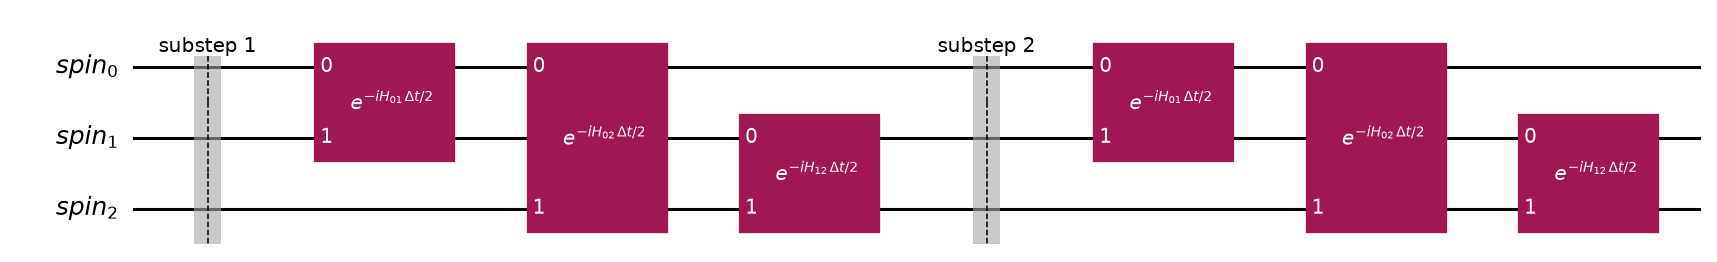

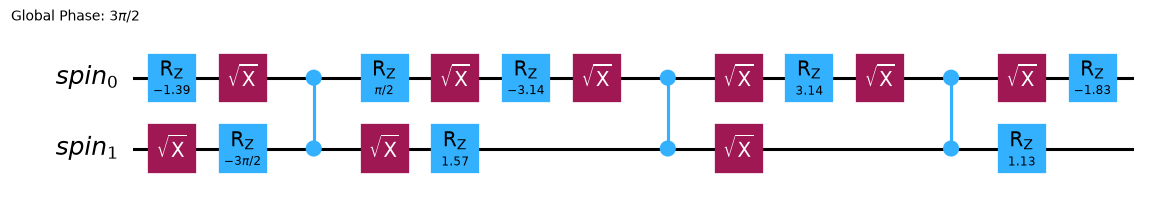

In [8]:
from IPython.display import Markdown, display
from qiskit import QuantumRegister
from qiskit.exceptions import MissingOptionalLibraryError

number_of_trottersteps = 300  # recorded samples, including t = 0
trotter_timestep = 0.0025     # seconds between recorded samples
trotter_reps = 2              # Trotter substeps per recorded dwell
circuit = pair_block_step(hamiltonian_qiskit, trotter_timestep, trotter_reps)

exact = expm(-1j * trotter_timestep * hamiltonian_qiskit.to_matrix())
organizer = transpile(PauliEvolutionGate(hamiltonian_qiskit, trotter_timestep, synthesis=LieTrotter()).definition,
                      basis_gates=["rx", "ry", "rz", "h", "cx"], optimization_level=0)
table = ["| Circuit per 2.5 ms dwell | CX | Two-qubit depth | Infidelity per dwell |", "|---|---|---|---|"]
for label, qc in (("Organizer: one first-order step", organizer),
                  ("Pair blocks, 1 substep", pair_block_step(hamiltonian_qiskit, trotter_timestep, 1)),
                  (f"Pair blocks, {trotter_reps} substeps (used below)", circuit)):
    infidelity = 1 - abs(np.trace(exact.conj().T @ Operator(qc).data)) / len(exact)
    table.append(f"| {label} | {qc.count_ops().get('cx', 0)} | {qc.depth(lambda g: g.operation.num_qubits == 2)} | {infidelity:.1e} |")
display(Markdown("\n".join(table)))

# Drawn for the selected molecule with spin i on qubit i (load_molecule keeps struqture's site order).
h_draw = load_molecule(molecule_name[-1])[0]
blocks = pair_block_step(h_draw, trotter_timestep, trotter_reps, synthesize=False)
per = len(blocks.data) // trotter_reps
dwell = QuantumCircuit(QuantumRegister(h_draw.num_qubits, "spin"))
for k, inst in enumerate(blocks.data):
    i, j = (blocks.find_bit(q).index for q in inst.qubits)
    if k % per == 0:
        dwell.barrier(label=f"substep {k // per + 1}")
    gate = inst.operation.copy()
    gate.label = fr"$e^{{-iH_{{{i}{j}}}\,\Delta t/{trotter_reps}}}$"
    dwell.append(gate, [i, j])
one = QuantumCircuit(QuantumRegister(2, "spin"))
one.append(blocks.data[0].operation, [0, 1])
native = transpile(one, basis_gates=["cz", "rz", "sx", "x"], optimization_level=3, seed_transpiler=7)
try:  # Qiskit's matplotlib drawer needs pylatexenc, installed by the first cell
    display(dwell.draw("mpl", style="iqp", fold=-1))
    display(native.draw("mpl", style="iqp", fold=-1))
except MissingOptionalLibraryError:
    print(dwell.draw("text")); print(native.draw("text"))

### 5. Initial states: complete X basis

Use $R_y(\pi/2)|0\rangle=|+\rangle$ for bit 0 and $R_y(-\pi/2)|0\rangle=|-\rangle$ for bit 1. Each product state has total Pauli-X eigenvalue $N-2\,\mathrm{popcount}(b)$. Enumerate all $2^N$ bit tuples and bind one parameter per qubit. The original observables use Pauli X/Y rather than spin X/Y divided by two; normalized spectra are unchanged by the common scale factor.


In [9]:
qc_init_template, phi, bits_list, param_maps = x_basis(number_spins)
assert len(bits_list) == 2**number_spins
for bits, parameters in zip(bits_list, param_maps):
    print(bits, "Xsum eigenvalue:", sum(1-2*b for b in bits))
qc_init_template.draw(output="text")

(0, 0, 0) Xsum eigenvalue: 3
(0, 0, 1) Xsum eigenvalue: 1
(0, 1, 0) Xsum eigenvalue: 1
(0, 1, 1) Xsum eigenvalue: -1
(1, 0, 0) Xsum eigenvalue: 1
(1, 0, 1) Xsum eigenvalue: -1
(1, 1, 0) Xsum eigenvalue: -1
(1, 1, 1) Xsum eigenvalue: -3


┌────────────┐
q_0: ┤ Ry(phi[0]) ├
     ├────────────┤
q_1: ┤ Ry(phi[1]) ├
     ├────────────┤
q_2: ┤ Ry(phi[2]) ├
     └────────────┘

### 6 Simulation with Qiskit's *Estimator*

In this step we use one of the backends in qiskit to perform a Trotterized time-evolution and find the time dependence of total magnetization for our system of interest.

### 6.1 Observables

To reconstruct the spectrum in the rotating frame, we need the transverse magnetization in both $x$ and $y$ directions. Total transverse operators
$$
\hat I_{x/y}^{\rm tot}=\sum_k \hat I_k^{\,x/y}
$$
What we record each time step is
$
\langle \hat I_x^{\rm tot}(t)\rangle 
$
and 
$
\langle \hat I_y^{\rm tot}(t)\rangle \, .
$

These two signals provide the time-dependent expectation values used in the Fourier transform ($C_{xx}(t) $ and $C_{yx}(t)$ ).

In [10]:
obs_x = SparsePauliOp.from_sparse_list(
    [("X", [i], 1.0) for i in range(number_spins)], num_qubits=number_spins
)
obs_y = SparsePauliOp.from_sparse_list(
    [("Y", [i], 1.0) for i in range(number_spins)], num_qubits=number_spins
)

### 6.2 Simulations and finding the expextation values

In [11]:
# Incremental statevectors produce the same local expectations without repeatedly
# simulating the whole growing prefix. This speedup is specific to local simulation.
RUN_FULL_ESTIMATOR = False

if RUN_FULL_ESTIMATOR:
    # Prebuild the parametric circuit at each step: U^n composed after the init template.
    circuits_per_step = []
    c = QuantumCircuit(number_spins)
    c = c.compose(qc_init_template)  # still parametric in phi
    circuits_per_step.append(c)
    
    for _ in range(1, number_of_trottersteps):
        c = c.compose(circuit)  # append one more Trotter step
        circuits_per_step.append(c)
    
    number_of_initializations = len(bits_list)
    exp_x = np.zeros((number_of_initializations, number_of_trottersteps))
    exp_y = np.zeros((number_of_initializations, number_of_trottersteps))
    
    estimator = Estimator()
    
    # Batch all initial states for each step to minimize overhead
    for k, circ in enumerate(circuits_per_step):
        pubs = []
        for m in range(number_of_initializations):
            pubs.append((circ, [obs_x, obs_y], param_maps[m]))  # pass parameter_values per pub
        job = estimator.run(pubs)
        results = job.result()  # list-like; one result per pub
        for m, res in enumerate(results):
            evs = res.data.evs  # [⟨obs_x⟩, ⟨obs_y⟩]
            exp_x[m, k] = evs[0]
            exp_y[m, k] = evs[1]
else:
    _, _, expectations = correlations(
        hamiltonian_qiskit, dt=trotter_timestep,
        samples=number_of_trottersteps, step=circuit)
    exp_x, exp_y = expectations

# Check a bound nontrivial preparation at a nonzero time using Estimator V2.
check_step = min(7, number_of_trottersteps-1)
check_circuit = qc_init_template.assign_parameters(param_maps[1])
for _ in range(check_step):
    check_circuit = check_circuit.compose(circuit)
check = Estimator().run([(check_circuit, [obs_x, obs_y])]).result()[0].data.evs
np.testing.assert_allclose(check, [exp_x[1, check_step], exp_y[1, check_step]], atol=1e-10)
print("Estimator V2 check passed:", check)

Estimator V2 check passed: [ 0.22938311 -0.77996054]


Above we calculate the expectation value for every spins. Now we have to sum over all spins. Additionally we add $0$ to increase the resolution of the spectrum.

\begin{equation*}
\mathrm{Tr}\!\big( \hat I_{x/y}^{\rm tot}(t)\, \hat I_x^{\rm tot}(0)\big)
\;=\;
\sum_{n} m_{x,n}(0)\, \langle m_{x,n}(t)\,|\, \hat I_{x/y}^{\rm tot}\,|\, m_{x,n}(t)\rangle,
\end{equation*}

In [12]:
# Expectation values.
c_xx = np.zeros(number_of_trottersteps)
c_yx = np.zeros(number_of_trottersteps)

# Perform vectorized calculations
mx_0 = exp_x[:, 0]
for i in range(number_of_trottersteps):
    c_xx[i] = np.sum(mx_0 * exp_x[:, i], axis=0)
    c_yx[i] = np.sum(mx_0 * exp_y[:, i], axis=0)

# --- apply a single exponential window before FFT ---
noise_strength = 5.0  # s^-1 (choose per system/step size)
times = np.arange(number_of_trottersteps) * trotter_timestep
window = np.exp(-noise_strength * times)
c_xx = c_xx * window
c_yx = c_yx * window

## 7. Finding the Spectrum

In this step, we perform a Fourier transform of the correlation functions to find the spectrum (a detailed derivation fo the spectral function can be found in the paper [arXiv:2404.18903](https://arxiv.org/abs/2404.18903))

$$
S(\omega)
\;=\;
\,\mathrm{Re}\!\int_{0}^{\infty} \! dt\; e^{-i(\omega-\bar\omega)t - \Gamma t}\,
\mathrm{Tr} \left( \hat I_x^{\rm tot}(t)\,\hat I_x^{\rm tot}(0) \right)
\;-\;
\,\mathrm{Im}\!\int_{0}^{\infty} \! dt\; e^{-i(\omega-\bar\omega)t - \Gamma t}\,
\mathrm{Tr} \left( \hat I_y^{\rm tot}(t)\,\hat I_x^{\rm tot}(0) \right).
$$

where $\Gamma$ is the effective decoherence rate that physically arises due to the interaction of nuclear spin with its environment or simply an artificial decay to perform the Fourier transform.

In [13]:
# Use the actual bins of the length-(2N-1) transform after downsampling.
def time_signal_to_spectrum(
    c_xx: np.ndarray,
    c_yx: np.ndarray,
    trotter_timestep: float,
    number_of_trottersteps: int,
    Hz_to_ppm_conversion: float,
    chem_shift_hz: float,
) -> Tuple[np.ndarray[Any, Any], np.ndarray[Any, Any]]:
    """Calculate the full spectrum from the computed expectation values via a Fourier Transform.

    Args:
        m_avg_z (np.ndarray): The first expectation value (c_xx)
        m_avg_y (np.ndarray): The second expectation value (c_yx)
        N_max (int): Number of Trotter steps.
        trotter_timestep (float): The Trotter timestep.
        Hz_to_ppm_conversion (float): Conversion factor from frequency to ppm.
        chem_shift_hz (float): The chemical shift of the input Hamiltonian (in Hz).

    Returns:
        Tuple[np.ndarray, np.ndarray]: A tuple containing:
            - **spectrum_full (np.ndarray):** The calculated spectrum.
            - **ppm (np.ndarray):** The ppm array to plot the full spectrum against.
    """
    spectrum_full = np.zeros(c_xx.shape[0], dtype=np.float64)

    m_avg_z = fft_causal(c_xx)
    m_avg_y = fft_causal(c_yx)

    frequencies = np.fft.fftshift(np.fft.fftfreq(2 * number_of_trottersteps - 1, d=trotter_timestep))[::2]

    # And now we have the frequency axis in ppm:
    # we need to shift the frequencies by twice the chemical input shift and then by the reference
    # energy, i.e. the energy of the honomuclear isotope (H) times the magnetic field.
    
    # the chemical shift:
    chem_shift = 2 * chem_shift_hz / (2.0*np.pi/Hz_to_ppm_conversion) + 1e6

    # to have the frequency axis in ppm:
    ppm = (frequencies) * Hz_to_ppm_conversion - chem_shift

    spectrum_full = m_avg_z.real + m_avg_y.imag

    spectrum_full /= np.max(np.abs(spectrum_full))

    return np.abs(spectrum_full), ppm


def fft_causal(f: np.ndarray) -> np.ndarray:
    """
    Performs the Fourier Transform of a causal signal by separating its even and odd parts.

    Args:
        f (np.ndarray): Input causal signal.

    Returns:
        np.ndarray: The complex Fourier Transform of the causal signal.
    """
    L = len(f)

    # Even part (symmetrize)
    fe = np.zeros(2 * L - 1, dtype=f.dtype)
    fe[:L] = f
    fe[L:] = f[:-1][::-1]
    fe /= 2

    # Odd part (antisymmetrize)
    fo = np.zeros(2 * L - 1, dtype=f.dtype)
    fo[:L] = f
    fo[L:] = -f[:-1][::-1]
    fo /= 2
    fo[0] = 0  # Avoids jump discontinuity at t=0

    # FFT with orthogonal normalization and shift
    fft_even = np.fft.fftshift(np.fft.fft(fe, norm="ortho"))
    fft_odd = np.fft.fftshift(np.fft.fft(fo, norm="ortho"))

    # Combine and downsample to original length
    combined_fft = (fft_even + fft_odd)[::2]

    return combined_fft

In [14]:
# Gyromagnetic ratio for 1H.
GYROMAGNETIC_RATIO_1H_RAD_S_T = 267_522_128.0

# Larmor/reference frequency in Hz at the given field.
reference_energy_hz = GYROMAGNETIC_RATIO_1H_RAD_S_T * field_T / (2 * np.pi)

# Conversion factor to go from Hz to ppm at this field: ppm = (Hz) * (1e6 / v0)
Hz_to_ppm_conversion = 1e6 / reference_energy_hz

In [15]:
spectrum_full, ppm = time_signal_to_spectrum(
    c_xx,
    c_yx,
    trotter_timestep,
    number_of_trottersteps,
    Hz_to_ppm_conversion=Hz_to_ppm_conversion,
    chem_shift_hz=chemical_shift_hz,
)

In [16]:
# The organizer's spectrum code above and the compact to_spectrum helper used below agree.
xx, yx, _ = correlations(hamiltonian_qiskit, dt=trotter_timestep, samples=number_of_trottersteps, step=circuit)
ppm_check, spectrum_check = to_spectrum(xx, yx, trotter_timestep, float(chemical_shift_hz), decay=noise_strength)
np.testing.assert_allclose(ppm_check, np.asarray(ppm, dtype=float))  # struqture returns CalculatorFloat
np.testing.assert_allclose(spectrum_check, spectrum_full, atol=1e-9)
print("Spectrum helpers agree.")

Spectrum helpers agree.


## 8. The Matching Task: Identifying Molecules with NMR Spectroscopy

Now that you have seen how to find the NMR spectrum of a given molecule, your task is to reproduce the spectrum for each molecule. Based on your simulated spectra, match them to the three reference spectra provided in the files to identify which spectrum belongs to Molecule A, Molecule B, and Molecule C.

### 8.1 All three molecules, and the linewidth of the reference

300 samples (0.75 s) resolve about 1.3 Hz, coarser than A's 0.9 Hz coupling. We record 4000 samples (10 s) and fit Γ, the only free parameter, to the references.

In [17]:
DT, LONG = 0.0025, 4000
refs = load_references(data_dir)
mol = {}
for name in "ABC":
    h, mean_z = load_molecule(name)
    mol[name] = dict(h=h, mean_z=mean_z,
                     short=correlations(h, dt=DT, samples=300, step=pair_block_step(h, DT, 2))[:2],
                     long=correlations(h, dt=DT, samples=LONG, step=pair_block_step(h, DT, 2))[:2])

def spectra(key, gamma):
    return [to_spectrum(*m[key], DT, m["mean_z"], gamma) for m in mol.values()]

base_matches, base_scores = match_spectra(spectra("short", 5.0), refs)
gammas = np.arange(1.0, 6.0, 0.05)
totals = [sum(s for *_, s in match_spectra(spectra("long", g), refs)[0]) for g in gammas]
gamma_ref = float(gammas[np.argmax(totals)])
matches, scores = match_spectra(spectra("long", gamma_ref), refs)
assert [j for _, j, _ in matches] == [j for _, j, _ in base_matches]
assign = {"ABC"[i]: j for i, j, _ in matches}
best = spectra("long", gamma_ref)
print(f"Best-fit reference decay: Γ = {gamma_ref:.2f} s⁻¹ (π = {np.pi:.2f}), a {gamma_ref/np.pi:.2f} Hz linewidth")
for i, j, s in matches:
    print(f"Molecule {'ABC'[i]} → spectrum {j+1}: cosine {s:.4f} (organizer settings {base_scores[i, j]:.3f}), "
          f"best wrong spectrum {np.delete(scores[i], j).max():.4f}")

Best-fit reference decay: Γ = 3.15 s⁻¹ (π = 3.14), a 1.00 Hz linewidth
Molecule A → spectrum 3: cosine 0.9996 (organizer settings 0.950), best wrong spectrum 0.0025
Molecule B → spectrum 2: cosine 0.9999 (organizer settings 0.933), best wrong spectrum 0.0026
Molecule C → spectrum 1: cosine 1.0000 (organizer settings 0.872), best wrong spectrum 0.0001


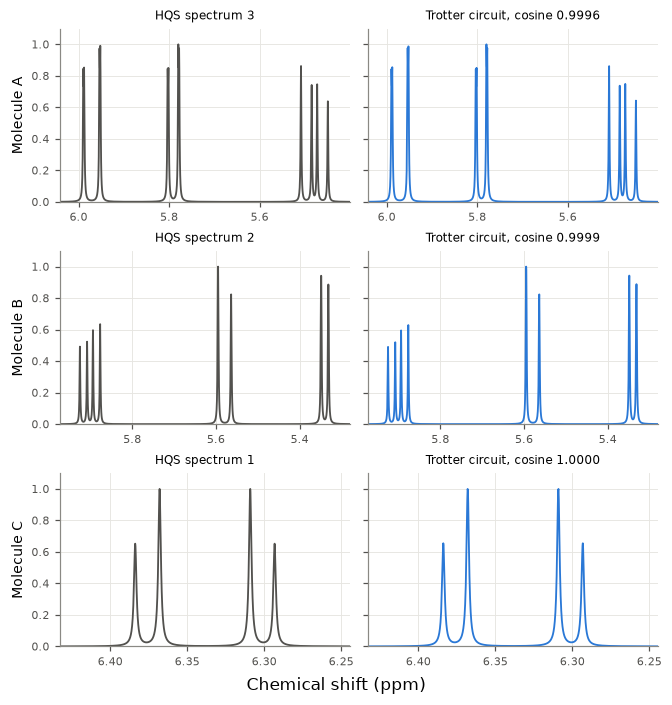

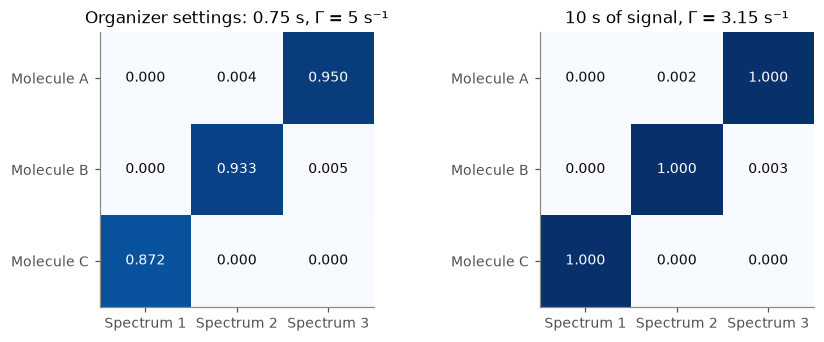

In [18]:
spectrum_grid([(f"Molecule {'ABC'[i]}", ref_xlim(j), [(f"HQS spectrum {j + 1}", *refs[j], REF),
                                                        (f"Trotter circuit, cosine {s:.4f}", *best[i], SIM)])
               for i, j, s in matches], "results/figures/matching.png")

fig, axes = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)
for ax, s, title in zip(axes, (base_scores, scores), ("Organizer settings: 0.75 s, Γ = 5 s⁻¹", f"10 s of signal, Γ = {gamma_ref:.2f} s⁻¹")):
    ax.imshow(s, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for (r, c), v in np.ndenumerate(s):
        ax.text(c, r, f"{v:.3f}", ha="center", va="center", color="white" if v > 0.6 else "#0b0b0b")
    ax.set(xticks=range(3), xticklabels=[f"Spectrum {k}" for k in (1, 2, 3)], yticks=range(3),
           yticklabels=[f"Molecule {m}" for m in "ABC"], title=title)
fig.savefig("results/figures/similarity.png", dpi=200)
plt.show()

Γ ≈ π s⁻¹, a Lorentzian FWHM of Γ/π = 1 Hz: the references are 1 Hz spectra. With that Γ every simulated spectrum lies on its reference.

## 9. Explore the Noise Tolerance

In NMR spectroscopy, the measured time-domain signal naturally decays over time due to various relaxation processes in the sample. In our simulation, we model this decay by applying an exponential window parameterized by the `noise_strength` (analogous to a decay rate in $s^{-1}$). 

As we increase the `noise_strength`, the resulting spectrum undergoes line broadening—peaks become wider and shorter. However, a spectrum remains analytically useful as long as the characteristic resonance peaks, particularly closely spaced multiplets resulting from scalar ($J$) couplings, remain distinguishable from one another.

### Exercise: Determining the Limit of Resolution

For each of the provided molecules (A, B, and C), systematically sweep the `noise_strength` parameter. Your goal is to determine the **maximum tolerable decay rate** that can be applied to the time signal before the resulting spectrum loses its analytical utility. 

1. Start with a low `noise_strength` (e.g., $0.1 \ s^{-1}$) and gradually increase it.
2. At each step, compare your simulated spectrum against the high-resolution HQS Spectrum Tools reference.
3. Record the highest `noise_strength` for each molecule where the distinct peaks are still visually resolvable. 

Finally, consider how the maximum tolerable noise strength relates to the specific parameters of the system's Hamiltonian. Is it related to the $J$-coupling strength?

### 9.1 Sweeping Γ with a resolution criterion

(a) The spectrum shows as many peaks as the 1 Hz reference (`find_peaks`, prominence 2 %). (b) Multiplet structure: lines closer than 2 Hz count as one, ignoring the sub-hertz couplings of A and B.

Line positions come from diagonalizing H, at $(E_j-E_i)/2\pi$ with intensity $|\langle i|I^+|j\rangle|^2$. Two equal Lorentzians lose their dip at a spacing of FWHM/√3 (Sparrow), so $\Gamma_{max} \le \sqrt{3}\,\pi\,\Delta\nu_{min} \approx 5.4\,\Delta\nu_{min}$. At 1 Hz linewidth this merges lines closer than 0.58 Hz, which (a) accounts for. Γ is bisected to 0.01 s⁻¹. The figure shows each spectrum at increasing Γ.

A (a): 12 features, Δν_min =  0.94 Hz → Γ_max ∈ [4.10, 4.11] s⁻¹, Γ_max/Δν_min = 4.36; with prominence 1 % / 5 %: 4.3 / 3.7
A (b):  8 features, Δν_min =  6.08 Hz → Γ_max ∈ [26.23, 26.24] s⁻¹, Γ_max/Δν_min = 4.32; with prominence 1 % / 5 %: 28.2 / 22.6
B (a):  8 features, Δν_min =  7.01 Hz → Γ_max ∈ [28.19, 28.20] s⁻¹, Γ_max/Δν_min = 4.02; with prominence 1 % / 5 %: 30.2 / 24.3
B (b):  8 features, Δν_min =  7.01 Hz → Γ_max ∈ [28.19, 28.20] s⁻¹, Γ_max/Δν_min = 4.02; with prominence 1 % / 5 %: 30.2 / 24.3
C (a):  4 features, Δν_min =  7.92 Hz → Γ_max ∈ [26.99, 27.00] s⁻¹, Γ_max/Δν_min = 3.41; with prominence 1 % / 5 %: 28.1 / 24.6
C (b):  4 features, Δν_min =  7.92 Hz → Γ_max ∈ [26.99, 27.00] s⁻¹, Γ_max/Δν_min = 3.41; with prominence 1 % / 5 %: 28.1 / 24.6


The assignment survives up to Γ = 3000 s⁻¹ (end of scan)


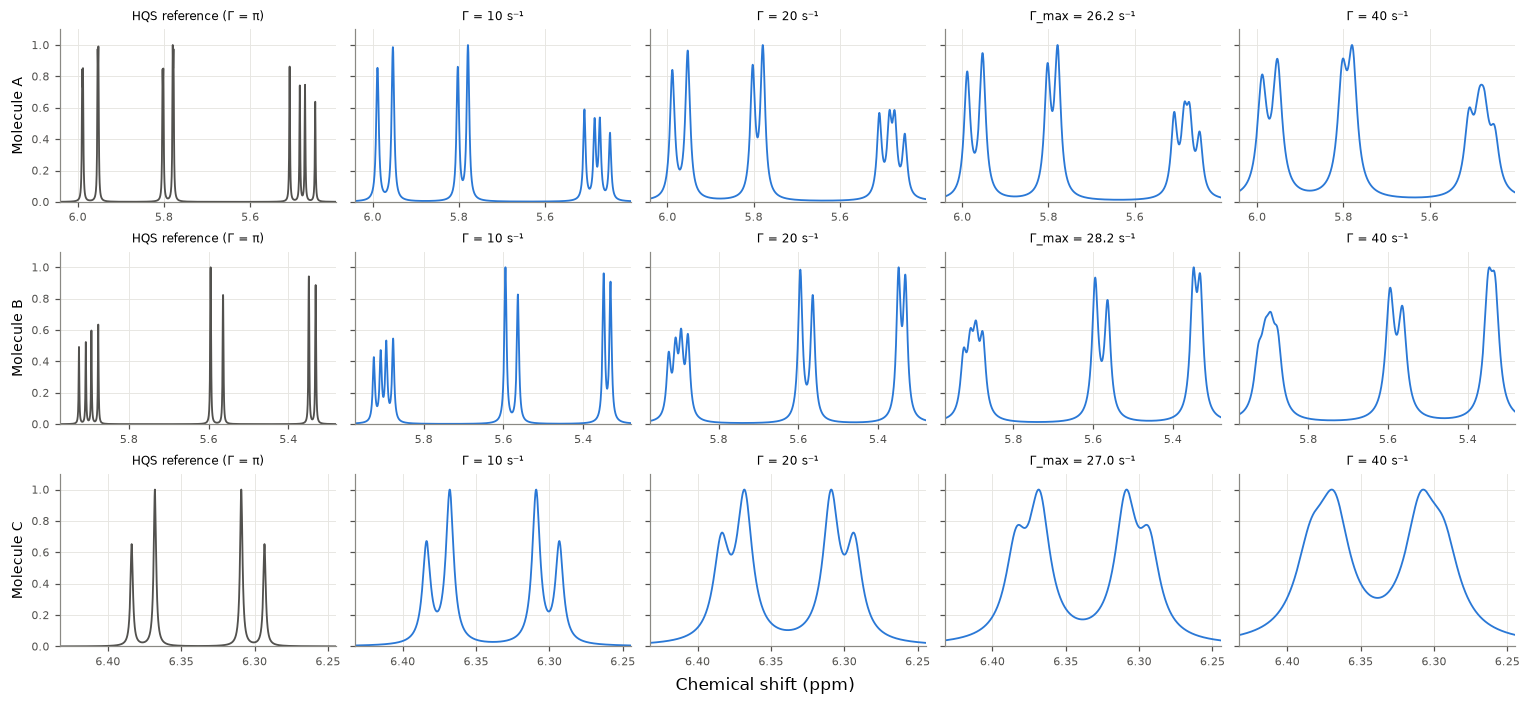

In [19]:
CONV = 1e6 / (267_522_128.0 * 11.7433 / (2 * np.pi))  # ppm per Hz

def ppm_of(freq_hz, mean_z):
    return freq_hz * CONV - (mean_z * CONV / np.pi + 1e6)

def stick_lines(h, min_rel=0.05):
    n = h.num_qubits
    energies, vectors = np.linalg.eigh(h.to_matrix())
    raising = SparsePauliOp.from_sparse_list([(a, [k], c) for k in range(n) for a, c in (("X", 0.5), ("Y", 0.5j))],
                                             num_qubits=n).to_matrix()
    weight = np.abs(vectors.conj().T @ raising @ vectors) ** 2
    i, j = np.nonzero(weight > min_rel * weight.max())
    freqs = (energies[j] - energies[i]) / (2 * np.pi)
    return np.sort(freqs)

def peak_count(name, gamma, prominence=0.02):
    m = mol[name]
    return len(find_peaks(to_spectrum(*m["long"], DT, m["mean_z"], gamma)[1], prominence=prominence)[0])

def gamma_limit(name, target, lo, hi=300.0, prominence=0.02):
    assert peak_count(name, lo, prominence) >= target > peak_count(name, hi, prominence)
    while hi - lo > 0.01:
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if peak_count(name, mid, prominence) >= target else (lo, mid)
    return lo, hi

rows = []
for name in "ABC":
    m = mol[name]
    freqs = stick_lines(m["h"])
    p, s = best["ABC".index(name)]
    peaks = p[find_peaks(s, prominence=0.02)[0]]
    assert np.all(np.abs(ppm_of(freqs, m["mean_z"])[:, None] - peaks).min(axis=1) < CONV), name  # lines within 1 Hz of peaks
    gaps = np.diff(freqs)
    ref_peaks = len(find_peaks(refs[assign[name]][1], prominence=0.02)[0])
    for crit, merge in (("a", 1 / np.sqrt(3)), ("b", 2.0)):
        target = 1 + int(np.sum(gaps > merge))
        if crit == "a":
            assert target == ref_peaks, (name, target, ref_peaks)
        lo, hi = gamma_limit(name, target, gamma_ref)
        robust = [gamma_limit(name, target, gamma_ref, prominence=q)[0] if peak_count(name, gamma_ref, q) >= target
                  else np.nan for q in (0.01, 0.05)]
        k = np.flatnonzero(gaps > merge)[np.argmin(gaps[gaps > merge])]
        rows.append(dict(molecule=name, criterion=crit, features=target, dnu=float(gaps[k]), pair=freqs[k:k+2],
                         lo=lo, hi=hi, robust=robust))
        print(f"{name} ({crit}): {target:2d} features, Δν_min = {gaps[k]:5.2f} Hz → Γ_max ∈ [{lo:.2f}, {hi:.2f}] s⁻¹, "
              f"Γ_max/Δν_min = {lo/gaps[k]:.2f}; with prominence 1 % / 5 %: {robust[0]:.1f} / {robust[1]:.1f}")

order = [j for _, j, _ in matches]
flip = next((g for g in np.geomspace(gamma_ref, 3000, 80)
             if [j for _, j, _ in match_spectra(spectra("long", g), refs)[0]] != order), None)
print("The assignment survives up to Γ =", f"{flip:.0f} s⁻¹" if flip else "3000 s⁻¹ (end of scan)")

grid = []
for i, j, _ in matches:
    name = "ABC"[i]; m = mol[name]
    gmax = next(x["lo"] for x in rows if x["molecule"] == name and x["criterion"] == "b")
    panels = [("HQS reference (Γ = π)", *refs[j], REF)]
    for g, head in ((10, "Γ = 10 s⁻¹"), (20, "Γ = 20 s⁻¹"), (gmax, f"Γ_max = {gmax:.1f} s⁻¹"), (40, "Γ = 40 s⁻¹")):
        panels.append((head, *to_spectrum(*m["long"], DT, m["mean_z"], g), SIM))
    grid.append((f"Molecule {name}", ref_xlim(j), panels))
spectrum_grid(grid, "results/figures/decay_sweep.png")

Each row is one molecule and each column a larger decay rate. At Γ = 10 s⁻¹ the sub-hertz splittings of A and B are already gone, but every multiplet is still clear. Near Γ_max the dips between neighbouring lines become shallow, and at 40 s⁻¹ the doublets and doublets of doublets have merged into single humps. The chemical-shift groups survive much longer, which is why the matching in 8.1 is far more robust than the fine structure: the assignment does not change up to the end of our scan at 3000 s⁻¹.

### 9.2 Largest tolerable Γ per molecule

The intervals are printed above. A's multiplets survive about as much as those of B and C, but its 0.9 Hz splitting is gone after a few s⁻¹. One figure per criterion, each spectrum at Γ_max and at 1.5 Γ_max; in (a) the row of A zooms into its 0.94 Hz pair. Criterion (c), with resolution enhancement, follows in section 10.2.

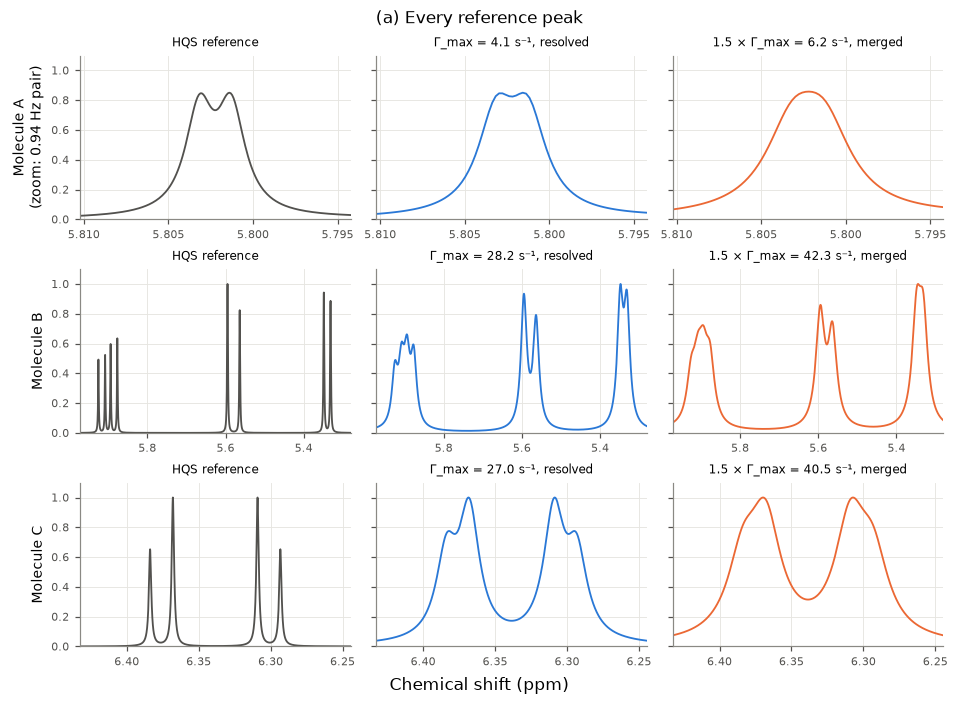

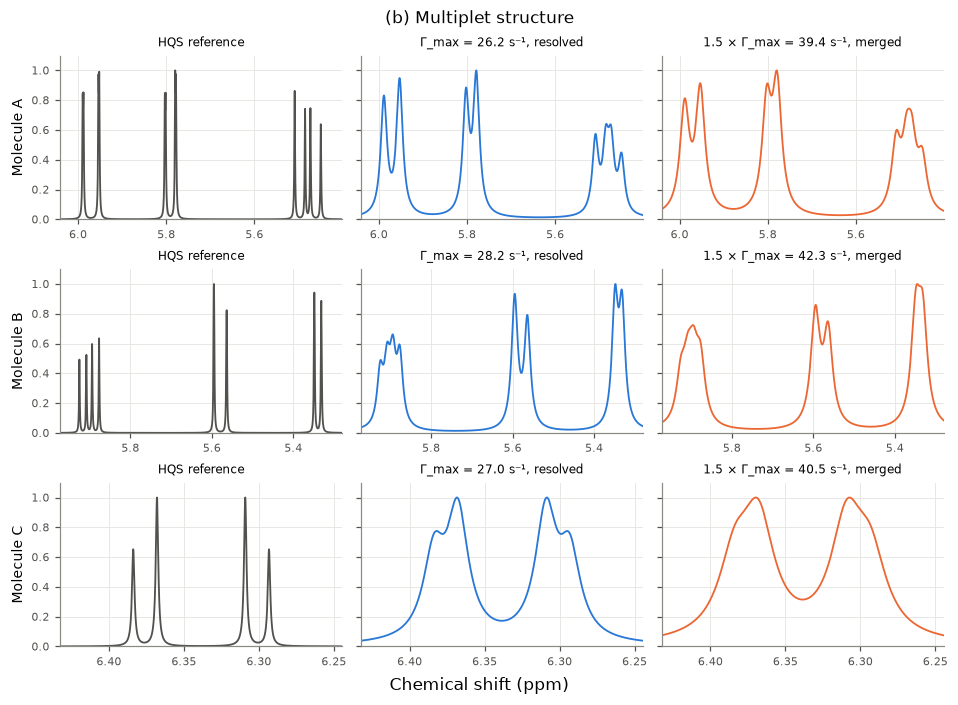

In [20]:
def limit_figure(crit, title, path):
    grid = []
    for i, j, _ in matches:
        name = "ABC"[i]; m = mol[name]
        r = next(x for x in rows if x["molecule"] == name and x["criterion"] == crit)
        label, xlim = f"Molecule {name}", ref_xlim(j)
        if r["dnu"] < 2:  # a sub-hertz pair is invisible at full width
            c, w = ppm_of(r["pair"].mean(), m["mean_z"]), 4 * CONV
            label, xlim = f"Molecule {name}\n(zoom: {r['dnu']:.2f} Hz pair)", (c + w, c - w)
        grid.append((label, xlim, [
            ("HQS reference", *refs[j], REF),
            (f"Γ_max = {r['lo']:.1f} s⁻¹, resolved", *to_spectrum(*m["long"], DT, m["mean_z"], r["lo"]), SIM),
            (f"1.5 × Γ_max = {1.5 * r['hi']:.1f} s⁻¹, merged", *to_spectrum(*m["long"], DT, m["mean_z"], 1.5 * r["hi"]), ALT)]))
    spectrum_grid(grid, path, title)

limit_figure("a", "(a) Every reference peak", "results/figures/limit_every_peak.png")
limit_figure("b", "(b) Multiplet structure", "results/figures/limit_multiplets.png")

In (a) only A's limit drops: its 0.94 Hz pair (zoomed row) is resolved at 4.1 s⁻¹ and merged at 6.2 s⁻¹. B and C have no sub-hertz splitting that the reference resolves, so they keep the same limit as in (b). In (b) all three molecules end up between 26 and 28 s⁻¹, because their closest multiplet lines are 6 to 8 Hz apart.

### 9.3 How the limit depends on J

The limit is set by the closest line pair that must stay resolved, and that spacing is a J coupling or a difference of two:

- A: 0.94 Hz from $J_{01}$ under (a); under (b) the inner gap of spin 2's doublet of doublets, $J_{12}-J_{02}$ = 17.9 − 11.8 = 6.1 Hz.
- B: the inner gap of spin 1's doublet of doublets, $J_{01}-J_{12}$ = 15.6 − 8.6 = 7.0 Hz. $J_{02}$ = 0.5 Hz is already unresolved in the reference.
- C: J = 7.9 Hz, strongly coupled (shift difference 36 Hz ≈ 4.6 J); the smaller outer lines of the roof effect merge first.

All limits fall on one line below the Sparrow bound (neighbors, unequal heights, 2 % dip). Rule of thumb: Γ/π must stay below about 1.2 times the smallest splitting you need.

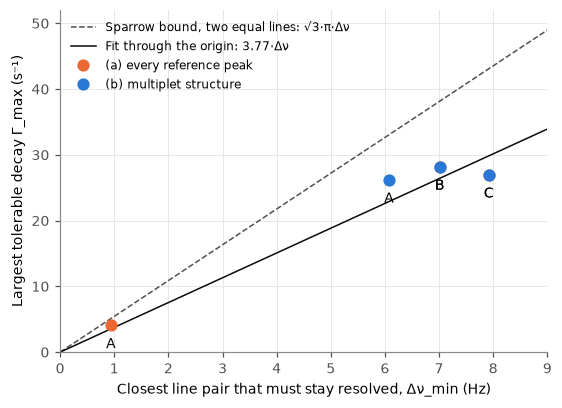

In [21]:
fig, ax = plt.subplots(figsize=(5, 3.6), constrained_layout=True)
d = np.array([r["dnu"] for r in rows]); g = np.array([r["lo"] for r in rows])
slope = float(d @ g / (d @ d))
x = np.linspace(0, 9, 50)
ax.plot(x, np.sqrt(3) * np.pi * x, color=REF, ls="--", lw=1, label="Sparrow bound, two equal lines: √3·π·Δν")
ax.plot(x, slope * x, color="#0b0b0b", lw=1, label=f"Fit through the origin: {slope:.2f}·Δν")
for crit, color, label in (("a", ALT, "(a) every reference peak"), ("b", SIM, "(b) multiplet structure")):
    sel = [r for r in rows if r["criterion"] == crit]
    ax.plot([r["dnu"] for r in sel], [r["lo"] for r in sel], "o", ms=7, color=color, label=label)
    for r in sel:
        ax.annotate(r["molecule"], (r["dnu"], r["lo"]), textcoords="offset points", xytext=(0, -15), ha="center")
ax.set(xlim=(0, 9), ylim=(0, 52), xlabel="Closest line pair that must stay resolved, Δν_min (Hz)",
       ylabel="Largest tolerable decay Γ_max (s⁻¹)")
ax.legend(loc="upper left", fontsize=8)
fig.savefig("results/figures/gamma_vs_splitting.png", dpi=200)
plt.show()

The fit gives Γ_max ≈ 3.8 × Δν_min, so the largest tolerable linewidth Γ/π is about 1.2 × Δν_min. In words: a multiplet stays readable as long as each line is no wider than about 1.2 times the distance to its neighbour. Since that distance is set by J, molecules with weaker couplings tolerate less noise, and the weakest coupling you still want to see decides.

## 10. Running on a quantum computer

The simulation above assumes perfect gates. This section makes the circuits cheap enough for current hardware, estimates how much noise they tolerate, and shows our results from ibm_marrakesh.

### 10.1 Fewer circuits and fewer gates

Initial states (advanced track): $Z^{\otimes N}$ commutes with H, swaps |+⟩ and |−⟩ and flips the sign of $I_x$ and $I_y$. A state and its bit-flipped partner therefore contribute the same $m\,f$, and m = 0 states contribute nothing. Keeping $b_0=0$, $m\neq0$ and counting twice leaves 4 of 8 circuits per time point for A and B and 1 of 4 for C. For large N, states can be sampled uniformly (weight $2^N m_b/K$) or with probability $\propto|m_b|$ (weight $\mathrm{sign}(m_b)\sum|m|/K$); both are unbiased.

Gates: Trotter error comes only from terms that do not commute, $\sum_{i<j}[H_i,H_j]\,t^2/2L$. `pair_block_step` exponentiates each spin pair's coupling, with its share of the Z terms, exactly as one 3-CX block (section 4.1). On ibm_marrakesh the three spins of A and B must be routed, which costs about 13.5 CZ per step with one substep. For C the transpiler merges all steps into one 3-CZ block.

In [22]:
for name in "ABC":
    h = mol[name]["h"]; n = h.num_qubits
    half = [b for b in product((0, 1), repeat=n) if b[0] == 0 and n - 2 * sum(b) != 0]
    ev = correlations(h, bits=half)[2]
    m = np.array([n - 2 * sum(b) for b in half])
    np.testing.assert_allclose(2 * np.einsum("b,abt->at", m, ev), np.array(correlations(h)[:2]), atol=1e-9)
    mol[name]["states"] = len(half)
    print(f"Molecule {name}: {len(half)} of {2**n} initial states reproduce the full trace")

Molecule A: 4 of 8 initial states reproduce the full trace
Molecule B: 4 of 8 initial states reproduce the full trace
Molecule C: 1 of 4 initial states reproduce the full trace


In [23]:
h = mol["A"]["h"]; n = h.num_qubits
bits = list(product((0, 1), repeat=n))
m_all = np.array([n - 2 * sum(b) for b in bits])
ev_all = correlations(h)[2]
full = np.einsum("b,abt->at", m_all, ev_all)
prob = np.abs(m_all) / np.abs(m_all).sum()
Ks, seeds = 2 ** np.arange(1, 10), 300
err = {"uniform": [], "|m|-weighted": []}
for K in Ks:
    e_u, e_w = [], []
    for seed in range(seeds):
        rng = np.random.default_rng(seed)
        u = rng.integers(0, len(bits), K)
        w = rng.choice(len(bits), K, p=prob)
        est_u = np.einsum("b,abt->at", m_all[u] * 2**n / K, ev_all[:, u])
        est_w = np.einsum("b,abt->at", np.sign(m_all[w]) * np.abs(m_all).sum() / K, ev_all[:, w])
        e_u.append(np.linalg.norm(est_u - full) / np.linalg.norm(full))
        e_w.append(np.linalg.norm(est_w - full) / np.linalg.norm(full))
    err["uniform"].append(np.mean(e_u)); err["|m|-weighted"].append(np.mean(e_w))

for K, a, b in zip(Ks, *err.values()):
    print(f"K = {K:3d}: uniform {a:.3f}, |m|-weighted {b:.3f}")

K =   2: uniform 0.937, |m|-weighted 0.751
K =   4: uniform 0.597, |m|-weighted 0.532
K =   8: uniform 0.434, |m|-weighted 0.362
K =  16: uniform 0.310, |m|-weighted 0.252
K =  32: uniform 0.231, |m|-weighted 0.188
K =  64: uniform 0.163, |m|-weighted 0.132
K = 128: uniform 0.120, |m|-weighted 0.092
K = 256: uniform 0.082, |m|-weighted 0.063
K = 512: uniform 0.056, |m|-weighted 0.044


Both estimators improve like 1/√K. For the same error, the |m|-weighted draw needs roughly a third fewer circuits, because it never spends a circuit on m = 0 and prefers the states that carry the most weight. For the two- and three-spin molecules here the exact symmetric sum (4 or 1 circuits per time point) is cheaper than either; sampling pays off for larger molecules.

In [24]:
for name in "ABC":
    m = mol[name]
    for reps in (1, 2, 4):
        row = []
        for kind, step in (("standard", trotter_step(m["h"], DT, reps)), ("pair blocks", pair_block_step(m["h"], DT, reps))):
            sig = correlations(m["h"], dt=DT, samples=LONG, step=step)[:2]
            cos = match_spectra([to_spectrum(*sig, DT, m["mean_z"], gamma_ref)], [refs[assign[name]]])[0][0][2]
            row.append(f"{kind} {step.count_ops().get('cx', 0):2d} CX, cosine {cos:.4f}")
        print(f"{name}, {reps} substeps: " + " | ".join(row))

A, 1 substeps: standard  9 CX, cosine 0.8735 | pair blocks  9 CX, cosine 0.9865
A, 2 substeps: standard 18 CX, cosine 0.9933 | pair blocks 18 CX, cosine 0.9996


A, 4 substeps: standard 36 CX, cosine 0.9996 | pair blocks 36 CX, cosine 0.9999


B, 1 substeps: standard  9 CX, cosine 0.9491 | pair blocks  9 CX, cosine 0.9959
B, 2 substeps: standard 18 CX, cosine 0.9977 | pair blocks 18 CX, cosine 0.9999


B, 4 substeps: standard 36 CX, cosine 0.9999 | pair blocks 36 CX, cosine 1.0000


C, 1 substeps: standard  3 CX, cosine 0.9998 | pair blocks  3 CX, cosine 1.0000
C, 2 substeps: standard  3 CX, cosine 1.0000 | pair blocks  3 CX, cosine 1.0000
C, 4 substeps: standard  3 CX, cosine 1.0000 | pair blocks  3 CX, cosine 1.0000


At the same CX count the pair blocks are always more accurate. With 9 CX, one substep of pair blocks reaches cosine 0.987 for A instead of 0.874, and two substeps (18 CX) match the standard construction with 36 CX. For C both give the exact evolution, because its single coupling forms one block.

### 10.2 Noise budget

Gate errors act as extra decay (Khedri et al., arXiv:2404.18903). We put a depolarizing channel with probability p after every CX of the standard step (4 substeps: 36 CX for A and B, 3 for C), evolve density matrices with the step's superoperator and fit the extra decay Γ_eff(p). $p_{max}$ is where Γ_eff uses up $\Gamma_{max}-\Gamma_{ref}$; without single-qubit, readout or shot noise it is an optimistic bound. The second cell repeats this for pair blocks, the third compares Trotter substeps at fixed p.

In [25]:
PAULI2 = [np.kron(Pauli(a).to_matrix(), Pauli(b).to_matrix()) for a in "IXYZ" for b in "IXYZ"]

def noisy_step(circuit, p):
    dep = SuperOp(Kraus([np.sqrt(1 - 15 * p / 16) * PAULI2[0]] + [np.sqrt(p / 16) * P for P in PAULI2[1:]]))
    channel = SuperOp(QuantumCircuit(circuit.num_qubits))
    for inst in circuit.data:
        q = [circuit.find_bit(b).index for b in inst.qubits]
        channel = channel.compose(SuperOp(inst.operation), qargs=q)
        if inst.operation.name == "cx":
            channel = channel.compose(dep, qargs=q)
    return channel.data

def noisy_signal(h, p, samples=LONG, reps=4, step=None):
    n = h.num_qubits
    template, _, bits, maps = x_basis(n)
    states = [Statevector.from_instruction(template.assign_parameters(mp)).data for mp in maps]
    rhos = np.column_stack([np.outer(s, s.conj()).reshape(-1, order="F") for s in states])
    obs = np.array([SparsePauliOp.from_sparse_list([(a, [i], 1) for i in range(n)], num_qubits=n)
                    .to_matrix().T.reshape(-1, order="F") for a in "XY"])  # Tr(O rho) = vec(O^T) . vec(rho)
    S = noisy_step(trotter_step(h, DT, reps) if step is None else step, p)
    weights = np.array([n - 2 * sum(b) for b in bits])
    out = np.empty((2, samples))
    for k in range(samples):
        out[:, k] = (obs @ rhos).real @ weights
        rhos = S @ rhos
    return out

h = mol["C"]["h"]
np.testing.assert_allclose(noisy_signal(h, 0.0, 300), np.array(correlations(h)[:2]), atol=1e-9)

def fit_gamma(name, signal, clean):
    m = mol[name]
    target = to_spectrum(*signal, DT, m["mean_z"], gamma_ref)
    loss = lambda g: -match_spectra([to_spectrum(*clean, DT, m["mean_z"], gamma_ref + g)], [target])[0][0][2]
    return minimize_scalar(loss, bounds=(0, 300), method="bounded").x

ps = np.array([3e-5, 1e-4, 3e-4, 1e-3, 3e-3])
limits = {(r["molecule"], r["criterion"]): r["lo"] for r in rows}
for name in "ABC":
    h = mol[name]["h"]
    mol[name]["noise"] = {}
    for reps in (4, 2):
        step = trotter_step(h, DT, reps)
        # the optimized circuit is the same product formula, only with fewer CX
        assert Operator(step).equiv(Operator(PauliEvolutionGate(h, DT, synthesis=LieTrotter(reps=reps)).definition))
        n_cx = int(step.count_ops().get("cx", 0))
        clean = correlations(h, dt=DT, samples=LONG, reps=reps)[:2]
        g_eff = np.array([fit_gamma(name, noisy_signal(h, p, reps=reps), clean) for p in ps])
        k = float(ps @ g_eff / (ps @ ps))
        res = mol[name]["noise"][reps] = dict(n_cx=n_cx, per_cx=k * DT / n_cx,
                                              p_max={c: (limits[name, c] - gamma_ref) / k for c in "ab"})
        print(f"{name}, {reps} substeps: {n_cx:2d} CX per step, Γ_eff ≈ {k:.3g}·p s⁻¹ = {res['per_cx']:.2f} × CX × p / Δt; "
              f"p_max ≈ {res['p_max']['b']:.1e} (multiplets), {res['p_max']['a']:.1e} (every reference peak)")

A, 4 substeps: 36 CX per step, Γ_eff ≈ 1.15e+04·p s⁻¹ = 0.80 × CX × p / Δt; p_max ≈ 2.0e-03 (multiplets), 8.3e-05 (every reference peak)


A, 2 substeps: 18 CX per step, Γ_eff ≈ 6.17e+03·p s⁻¹ = 0.86 × CX × p / Δt; p_max ≈ 3.7e-03 (multiplets), 1.5e-04 (every reference peak)


B, 4 substeps: 36 CX per step, Γ_eff ≈ 1.09e+04·p s⁻¹ = 0.76 × CX × p / Δt; p_max ≈ 2.3e-03 (multiplets), 2.3e-03 (every reference peak)


B, 2 substeps: 18 CX per step, Γ_eff ≈ 6.1e+03·p s⁻¹ = 0.85 × CX × p / Δt; p_max ≈ 4.1e-03 (multiplets), 4.1e-03 (every reference peak)


C, 4 substeps:  3 CX per step, Γ_eff ≈ 1.2e+03·p s⁻¹ = 1.00 × CX × p / Δt; p_max ≈ 2.0e-02 (multiplets), 2.0e-02 (every reference peak)


C, 2 substeps:  3 CX per step, Γ_eff ≈ 1.2e+03·p s⁻¹ = 1.00 × CX × p / Δt; p_max ≈ 2.0e-02 (multiplets), 2.0e-02 (every reference peak)


In [26]:
for name in "ABC":
    m = mol[name]
    step = pair_block_step(m["h"], DT, 2)
    clean = correlations(m["h"], dt=DT, samples=LONG, step=step)[:2]
    g_eff = np.array([fit_gamma(name, noisy_signal(m["h"], p, step=step), clean) for p in ps])
    k = float(ps @ g_eff / (ps @ ps))
    m["pair"] = dict(n_cx=int(step.count_ops().get("cx", 0)), p_max={c: (limits[name, c] - gamma_ref) / k for c in "ab"})
    print(f"{name}: pair blocks, 2 substeps, {m['pair']['n_cx']} CX per step → p_max ≈ {m['pair']['p_max']['b']:.1e} "
          f"(multiplets); standard 4 substeps: {m['noise'][4]['p_max']['b']:.1e}")

A: pair blocks, 2 substeps, 18 CX per step → p_max ≈ 3.7e-03 (multiplets); standard 4 substeps: 2.0e-03


B: pair blocks, 2 substeps, 18 CX per step → p_max ≈ 4.1e-03 (multiplets); standard 4 substeps: 2.3e-03


C: pair blocks, 2 substeps, 3 CX per step → p_max ≈ 2.0e-02 (multiplets); standard 4 substeps: 2.0e-02


Halving the CX count doubles the tolerable error, to about 4 × 10⁻³ per CX for A and B and 2 × 10⁻² for C. The best qubit pairs on ibm_marrakesh have a CZ error near 1.2 × 10⁻³ and the device median is 2.4 × 10⁻³ (calibration file in `results/hardware/`), so on gate errors alone the multiplets would survive. Decoherence during long circuits, which this model leaves out, is what limits A and B in practice.

A, p = 0.0003: 1 substeps 0.8927, 2 substeps 0.9782, 4 substeps 0.9507, 8 substeps 0.8793 → best 2


A, p = 0.001: 1 substeps 0.8956, 2 substeps 0.9014, 4 substeps 0.7913, 8 substeps 0.6475 → best 2


A, p = 0.003: 1 substeps 0.8171, 2 substeps 0.7063, 4 substeps 0.5751, 8 substeps 0.4963 → best 1


B, p = 0.0003: 1 substeps 0.9540, 2 substeps 0.9774, 4 substeps 0.9380, 8 substeps 0.8505 → best 2


B, p = 0.001: 1 substeps 0.9287, 2 substeps 0.8782, 4 substeps 0.7547, 8 substeps 0.6213 → best 1


B, p = 0.003: 1 substeps 0.8026, 2 substeps 0.6728, 4 substeps 0.5638, 8 substeps 0.4971 → best 1


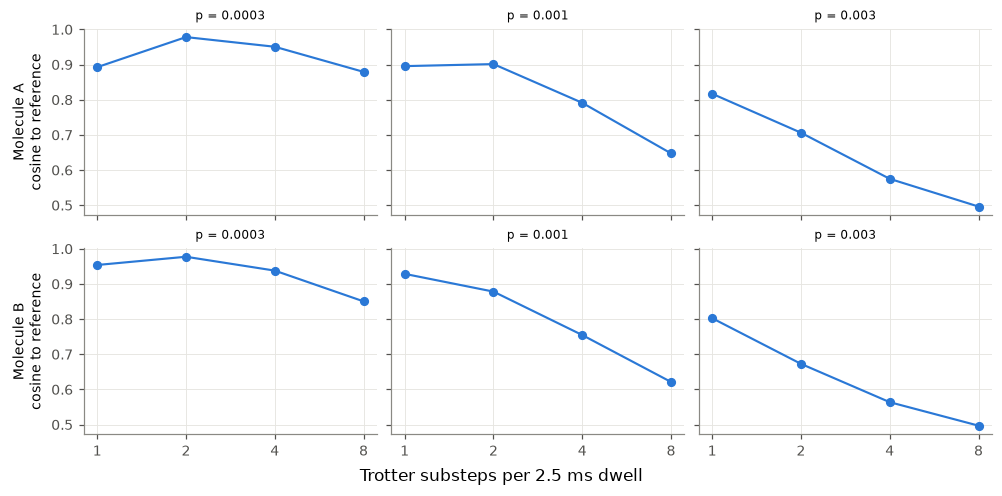

In [27]:
reps_list, p_list = (1, 2, 4, 8), (3e-4, 1e-3, 3e-3)
best_reps = {}
fig, axes = plt.subplots(2, 3, figsize=(9, 4.4), layout="constrained", sharex=True, sharey=True)
for ax_row, name in zip(axes, "AB"):
    m = mol[name]
    for ax, p in zip(ax_row, p_list):
        cs = [match_spectra([to_spectrum(*noisy_signal(m["h"], p, reps=r), DT, m["mean_z"], gamma_ref)],
                            [refs[assign[name]]])[0][0][2] for r in reps_list]
        best_reps[f"{name}@{p:g}"] = reps_list[int(np.argmax(cs))]
        ax.plot(reps_list, cs, "o-", ms=5, lw=1.4, color=SIM)
        ax.set_xscale("log", base=2)
        ax.set_xticks(reps_list, [str(r) for r in reps_list])
        ax.minorticks_off()
        ax.set_title(f"p = {p:g}", fontsize=8)
        print(f"{name}, p = {p:g}: " + ", ".join(f"{r} substeps {c:.4f}" for r, c in zip(reps_list, cs))
              + f" → best {best_reps[f'{name}@{p:g}']}")
    ax_row[0].set_ylabel(f"Molecule {name}\ncosine to reference")
fig.supxlabel("Trotter substeps per 2.5 ms dwell")
fig.savefig("results/figures/trotter_vs_noise.png", dpi=200)

Without noise, more substeps always help. Already at p = 10⁻³, two substeps are best for A and one for B, and at 3 × 10⁻³ a single substep wins for both: the extra depth costs more than the Trotter error it removes. This is why our hardware runs use one substep for A and B.

Shot noise limits how much resolution processing can win back. A Lorentz-Gauss window $e^{\Gamma t-(t/\tau)^2}$ undoes the known decay; $\tau = 2\sqrt{\ln 30}/\Gamma$ caps the noise gain at 30. With shot noise $\sigma_C=\sqrt{N\sum_b m_b^2/S}$ for S shots per circuit, every dip must be at least 2 % in the noiseless processed spectrum and at least 3σ of the noisy baseline.

In [28]:
t = np.arange(LONG) * DT

def lg_window(gamma, gain=30):
    tau = 2 * np.sqrt(np.log(gain)) / gamma  # the window's maximum, i.e. the noise gain, equals `gain`
    return np.exp(gamma * t - (t / tau) ** 2)

def shot_sigma(n, shots):
    m = n - 2 * np.array([sum(b) for b in product((0, 1), repeat=n)])
    return np.sqrt(n * np.sum(m ** 2) / shots)

def dip_margin(ppm, s, centers):
    margin = np.inf
    for a, b in zip(centers, centers[1:]):
        if (b - a) / CONV > 30:  # only neighbors inside one multiplet
            continue
        near = lambda x: np.abs(ppm - x) < 0.4 * CONV
        margin = min(margin, min(s[near(a)].max(), s[near(b)].max()) - s[(ppm > a) & (ppm < b)].min())
    return margin

def noisy_limit(name, shots, enhance, seeds=3):
    m = mol[name]
    freqs = stick_lines(m["h"])
    centers = ppm_of(np.array([g.mean() for g in np.split(freqs, np.flatnonzero(np.diff(freqs) > 2.0) + 1)]), m["mean_z"])
    sigma = shot_sigma(m["h"].num_qubits, shots)
    best = 0.0
    for gamma in np.arange(5.0, 150.0, 1.0):
        w = lg_window(gamma) if enhance else np.ones(LONG)
        decayed = np.array(m["long"]) * np.exp(-gamma * t)
        ppm, clean = to_spectrum(*(decayed * w), DT, m["mean_z"], 0)
        far = np.abs(ppm[:, None] - ppm_of(freqs, m["mean_z"])).min(axis=1) > 40 * CONV
        noise = np.mean([np.std(to_spectrum(*((decayed + np.random.default_rng(s).normal(0, sigma, decayed.shape)) * w),
                                            DT, m["mean_z"], 0)[1][far]) for s in range(seeds)])
        margin = dip_margin(ppm, clean, centers)
        if margin < 0.02 or margin < 3 * noise:
            break
        best = gamma
    return best

lg = {}
for name in "ABC":
    for shots in (1e3, 1e4, 1e5):
        raw, enh = noisy_limit(name, shots, False), noisy_limit(name, shots, True)
        lg[f"{name}@{shots:.0e}"] = (raw, enh)
        print(f"{name}, {shots:.0e} shots per circuit: Γ_max {raw:.0f} s⁻¹ with standard processing, "
              f"{enh:.0f} s⁻¹ with Lorentz-Gauss (× {enh / raw:.2f})")

A, 1e+03 shots per circuit: Γ_max 13 s⁻¹ with standard processing, 23 s⁻¹ with Lorentz-Gauss (× 1.77)
A, 1e+04 shots per circuit: Γ_max 18 s⁻¹ with standard processing, 32 s⁻¹ with Lorentz-Gauss (× 1.78)


A, 1e+05 shots per circuit: Γ_max 23 s⁻¹ with standard processing, 39 s⁻¹ with Lorentz-Gauss (× 1.70)


B, 1e+03 shots per circuit: Γ_max 15 s⁻¹ with standard processing, 25 s⁻¹ with Lorentz-Gauss (× 1.67)
B, 1e+04 shots per circuit: Γ_max 20 s⁻¹ with standard processing, 35 s⁻¹ with Lorentz-Gauss (× 1.75)


B, 1e+05 shots per circuit: Γ_max 24 s⁻¹ with standard processing, 43 s⁻¹ with Lorentz-Gauss (× 1.79)


C, 1e+03 shots per circuit: Γ_max 17 s⁻¹ with standard processing, 34 s⁻¹ with Lorentz-Gauss (× 2.00)


C, 1e+04 shots per circuit: Γ_max 22 s⁻¹ with standard processing, 42 s⁻¹ with Lorentz-Gauss (× 1.91)


C, 1e+05 shots per circuit: Γ_max 25 s⁻¹ with standard processing, 47 s⁻¹ with Lorentz-Gauss (× 1.88)


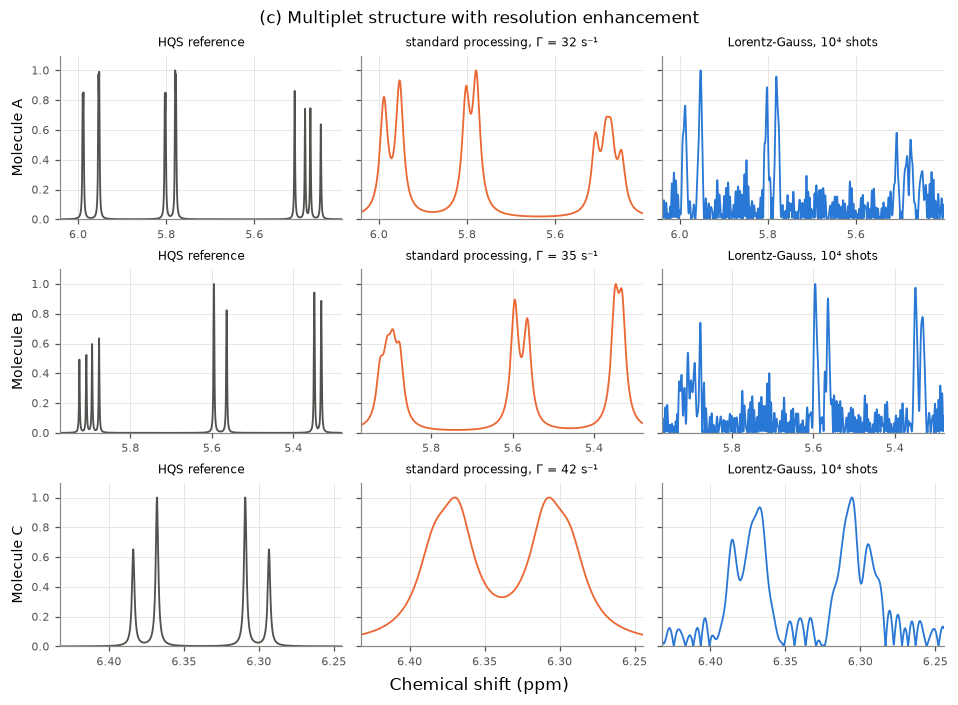

In [29]:
shots = 1e4
grid = []
for i, j, _ in matches:
    name = "ABC"[i]; m = mol[name]
    gamma = lg[f"{name}@{shots:.0e}"][1]
    clean = np.array(m["long"]) * np.exp(-gamma * t)
    measured = clean + np.random.default_rng(0).normal(0, shot_sigma(m["h"].num_qubits, shots), clean.shape)
    grid.append((f"Molecule {name}", ref_xlim(j), [
        ("HQS reference", *refs[j], REF),
        (f"standard processing, Γ = {gamma:.0f} s⁻¹", *to_spectrum(*clean, DT, m["mean_z"], 0), ALT),
        ("Lorentz-Gauss, 10⁴ shots", *to_spectrum(*(measured * lg_window(gamma)), DT, m["mean_z"], 0), SIM)]))
spectrum_grid(grid, "results/figures/resolution_enhancement.png", "(c) Multiplet structure with resolution enhancement")

More shots buy a few s⁻¹; a gain of 300 instead of 30 made Γ_max worse at 10⁴ shots. QPU time is about 0.62 ms per circuit and shot, so time points are the expensive part. The noiseless hardware circuit identifies every molecule from 10 time points and shows the multiplets from about 50 (curves zero-padded for display).

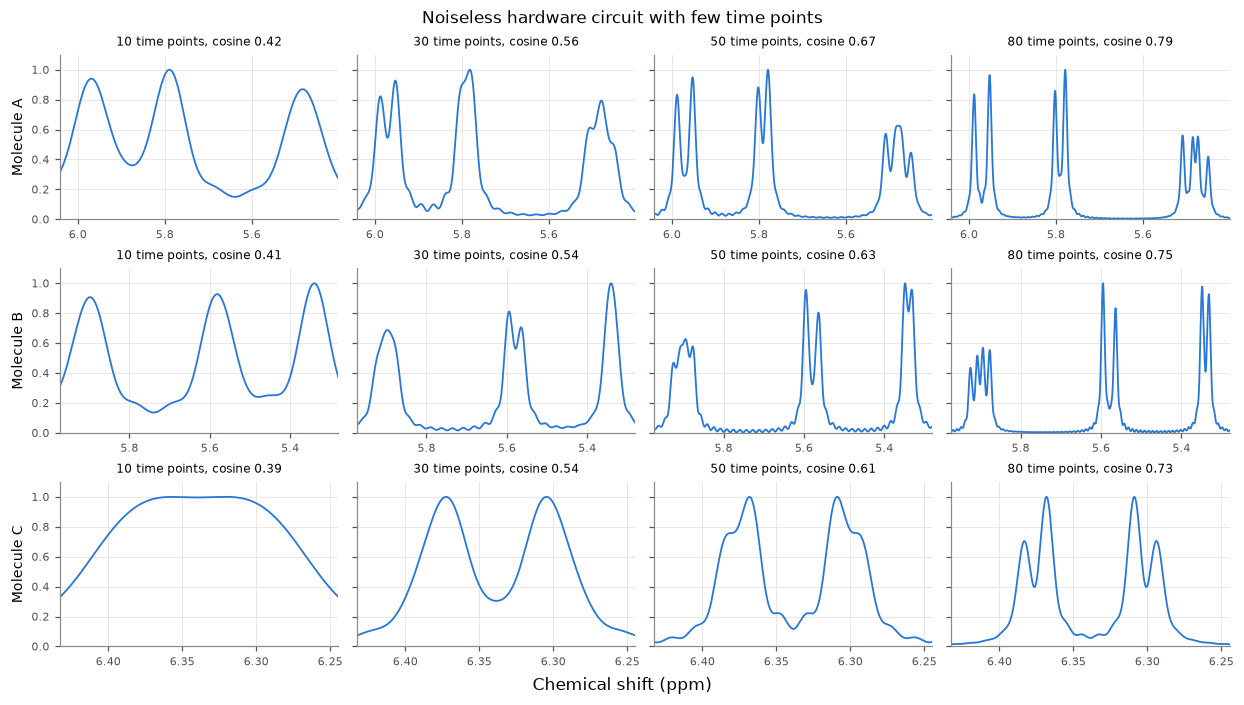

In [30]:
grid = []
for i, j, _ in matches:
    name = "ABC"[i]; m = mol[name]
    sig = np.array(correlations(m["h"], dt=DT, samples=80, step=pair_block_step(m["h"], DT, 1 if m["h"].num_qubits > 2 else 2))[:2])
    panels = []
    for K in (10, 30, 50, 80):
        p, s = to_spectrum(*np.pad(sig[:, :K], ((0, 0), (0, LONG - K))), DT, m["mean_z"], max(gamma_ref, 3 / (K * DT)))
        panels.append((f"{K} time points, cosine {match_spectra([(p, s)], refs)[1][0][j]:.2f}", p, s, SIM))
    grid.append((f"Molecule {name}", ref_xlim(j), panels))
spectrum_grid(grid, "results/figures/time_points.png", "Noiseless hardware circuit with few time points")

The number of time points K sets the frequency resolution, roughly 1/(K Δt). Ten points give about 40 Hz, enough to separate the chemical-shift groups that identify a molecule; 50 to 80 points (8 to 5 Hz) start to show the multiplets. On hardware every time point is another set of circuits, and for A and B each one is deeper than the last, so K is the main cost decision of a real run.

### 10.3 Results from ibm_marrakesh

The measured expectation values of our runs are stored in `results/hardware/hardware_data.npz`, so this cell needs no IBM account. A and B: 60 time points, 4 circuits each, 500 shots, one substep (up to 795 CZ); an earlier run with 50 points and 250 shots (`A50`, `B50` in the data file) gave the same assignment. C: 300 time points, 1000 shots, at most 3 CZ per circuit, on qubits 147–148, the best pair in the device calibration (`results/hardware/ibm_marrakesh_calibrations_*.csv`). Each row shows the reference, the same circuit without noise, and the hardware; spectra are zero-padded for display.

| Molecule | Time points | Cosine to right spectrum | Best wrong spectrum | Same circuit, noiseless |
|---|---|---|---|---|
| A | 60 | 0.595 | 0.036 | 0.707 |
| B | 60 | 0.569 | 0.028 | 0.683 |
| C | 300 | 0.920 | 0.021 | 0.989 |

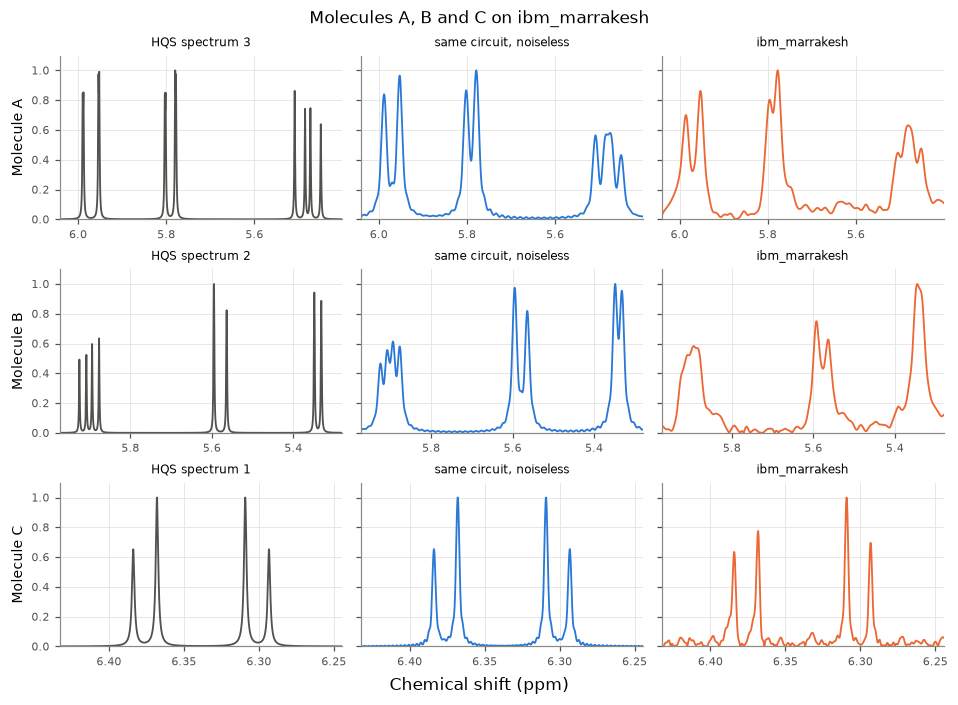

In [31]:
hw_data = np.load("results/hardware/hardware_data.npz")
grid = []
table = ["| Molecule | Time points | Cosine to right spectrum | Best wrong spectrum | Same circuit, noiseless |", "|---|---|---|---|---|"]
for name in "ABC":
    m = mol[name]; n = m["h"].num_qubits; j = assign[name]
    evs = hw_data[name]  # (initial states, time points, [<X_tot>, <Y_tot>])
    samples = evs.shape[1]
    states = [b for b in product((0, 1), repeat=n) if b[0] == 0 and n - 2 * sum(b) != 0]
    hw = 2 * np.einsum("b,bta->at", np.array([n - 2 * sum(b) for b in states]), evs)
    sim = np.array(correlations(m["h"], dt=DT, samples=samples, step=pair_block_step(m["h"], DT, 1 if n > 2 else 2))[:2])
    gw = max(gamma_ref, 3 / (samples * DT))
    hw_spec, sim_spec = (to_spectrum(*np.pad(s, ((0, 0), (0, LONG - samples))), DT, m["mean_z"], gw) for s in (hw, sim))
    sc, sim_cos = match_spectra([hw_spec], refs)[1][0], match_spectra([sim_spec], refs)[1][0][j]
    m["hw"] = dict(samples=samples, cos=float(sc[j]), wrong=float(np.delete(sc, j).max()), sim=float(sim_cos))
    table.append(f"| {name} | {samples} | {sc[j]:.3f} | {np.delete(sc, j).max():.3f} | {sim_cos:.3f} |")
    grid.append((f"Molecule {name}", ref_xlim(j), [(f"HQS spectrum {j + 1}", *refs[j], REF),
                 ("same circuit, noiseless", *sim_spec, SIM), ("ibm_marrakesh", *hw_spec, ALT)]))
display(Markdown("\n".join(table)))
spectrum_grid(grid, "results/figures/hardware_marrakesh.png", "Molecules A, B and C on ibm_marrakesh")

For C the four lines and the roof effect come out almost as in the noiseless circuit, because every circuit has at most 3 two-qubit gates, whatever the time point. For A and B the peak groups sit in the right places and the larger splittings are visible, but the lines are broader and the baseline is noisier: the late circuits have several hundred CZ gates, and their errors damp the signal like extra decay. For every molecule the right spectrum still scores more than ten times higher than the best wrong one.

A teammate ran the three molecules independently on ibm_marrakesh and on a second device, ibm_kingston, with their own analysis script (figure labels in German; K = time points, QPU seconds in the legends). Both devices reproduce the peak groups of every reference spectrum:

| Molecule | ibm_marrakesh: K, cosine | ibm_kingston: K, cosine |
|---|---|---|
| A | 45, 0.616 | 45, 0.642 |
| B | 45, 0.577 | 60, 0.608 |
| C | 80, 0.797 | 60, 0.778 |

These cosines come from that script, with other time points and processing, so they are not directly comparable with the table above.

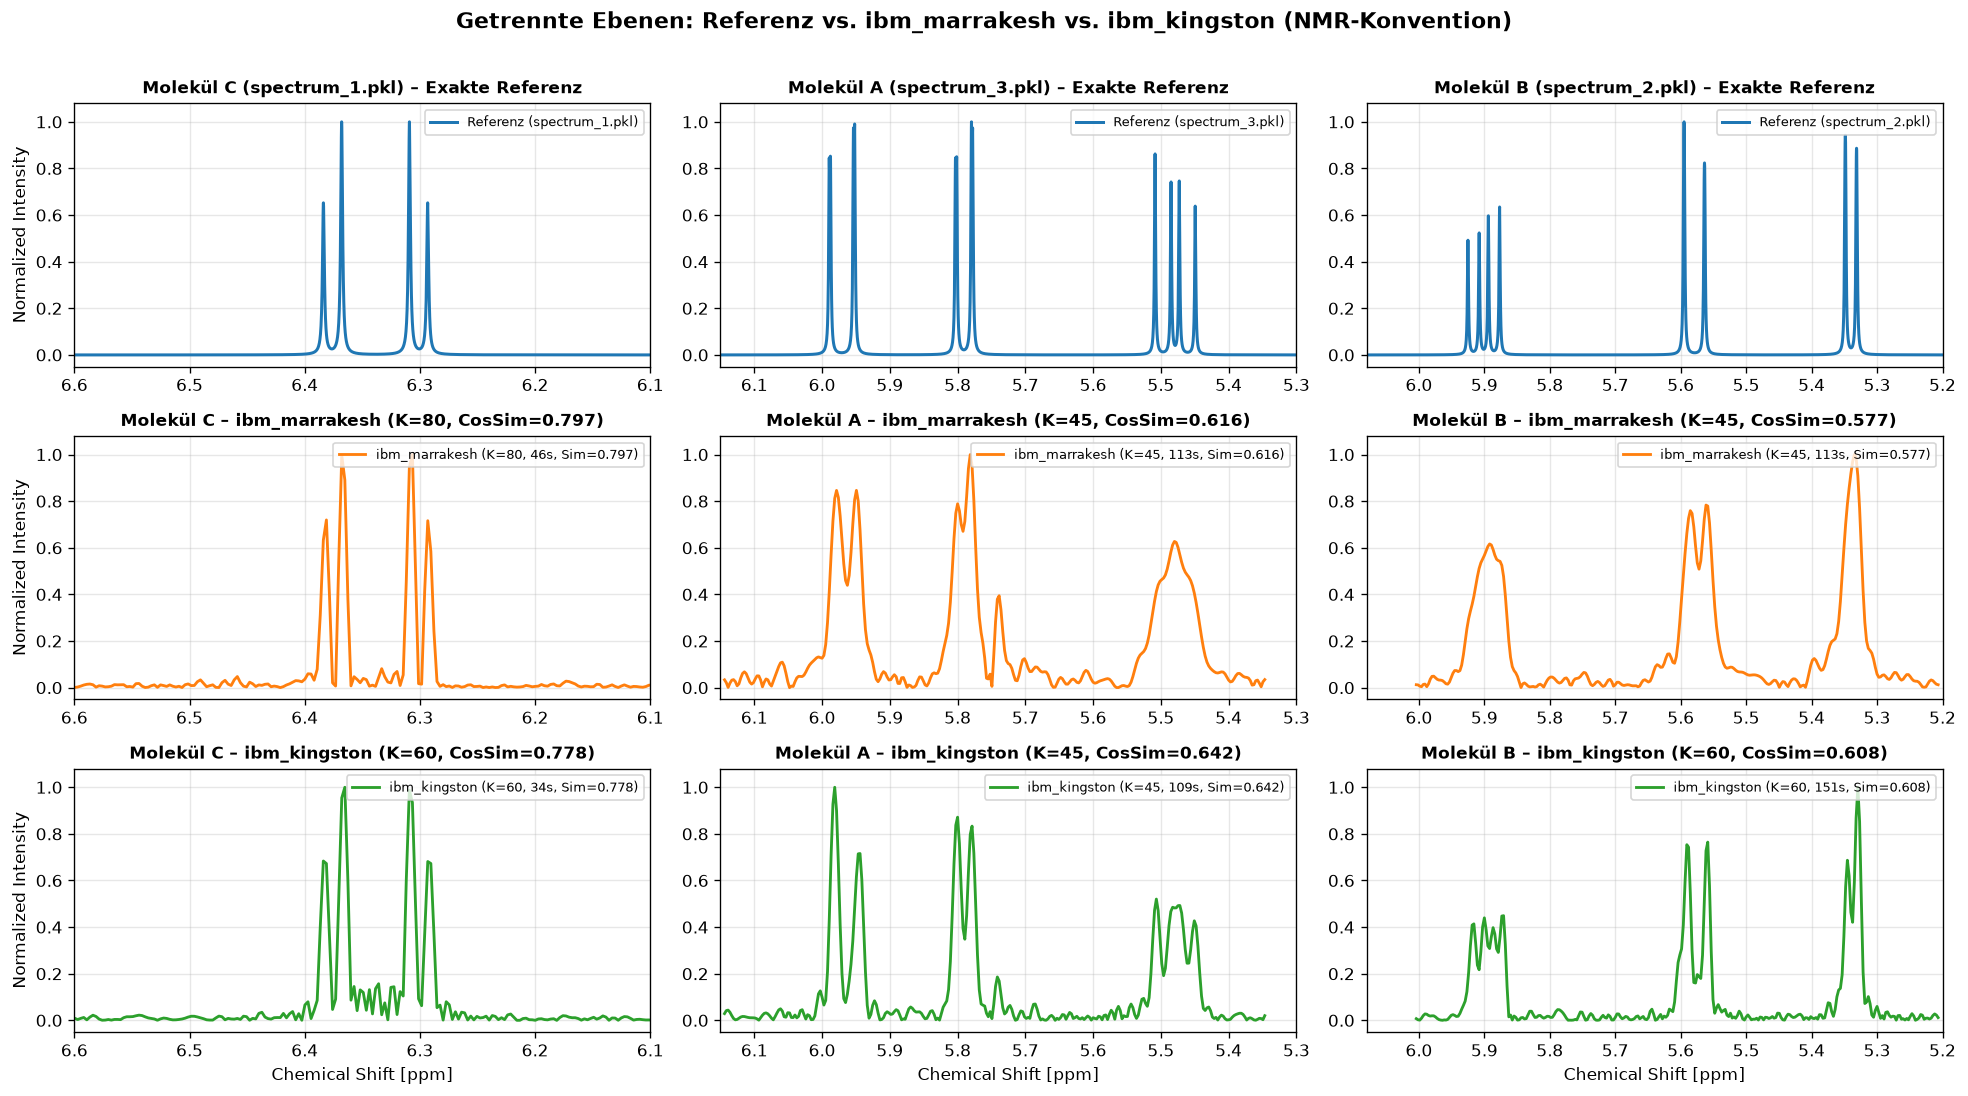

In [32]:
from IPython.display import Image
second_device = Path("results/figures/hardware_kingston_marrakesh_comparison.png")
if second_device.exists():
    display(Image(filename=str(second_device), width=1100))

To run it yourself (off by default): save an account with `QiskitRuntimeService.save_account(...)` and execute the notebook with `RUN_ON_HARDWARE=1`. Options: `HW_MOLECULE=A|B|C`, `HW_SAMPLES`, `HW_SHOTS` (default 250), `HW_CHUNK` (circuits per job, default 50), `HW_BACKEND=ibm_marrakesh`, `HW_TWIRL=1` (Pauli twirling), `HW_FAKE=1` (local dry run on FakeKingston). For C the qubit pair comes from the calibration CSV in `results/hardware/`.

In [33]:
import csv, os
RUN_ON_HARDWARE = os.environ.get("RUN_ON_HARDWARE") == "1"
if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime import EstimatorV2, QiskitRuntimeService
    from qiskit_ibm_runtime.fake_provider import FakeKingston
    from qiskit.transpiler import generate_preset_pass_manager

    name = os.environ.get("HW_MOLECULE", "C")
    samples = int(os.environ.get("HW_SAMPLES", 300 if name == "C" else 30))  # late A/B circuits get too deep
    shots = int(os.environ.get("HW_SHOTS", 250))
    h = mol[name]["h"]; n = h.num_qubits
    template, phi, bits, _ = x_basis(n)
    states = [b for b in bits if b[0] == 0 and n - 2 * sum(b) != 0]
    step = pair_block_step(h, DT, 1 if n > 2 else 2)  # 1 substep: 9 CX per step for A and B
    circuits = []
    for b in states:
        c = template.assign_parameters({phi[i]: (-1 if v else 1) * np.pi / 2 for i, v in enumerate(b)})
        for _ in range(samples):
            circuits.append(c)
            c = c.compose(step)
    if os.environ.get("HW_FAKE") == "1":
        backend = FakeKingston()
    elif os.environ.get("HW_BACKEND"):
        backend = QiskitRuntimeService().backend(os.environ["HW_BACKEND"])
    else:
        backend = QiskitRuntimeService().least_busy(operational=True, simulator=False)
    cal = next(Path("results/hardware").glob(f"{backend.name}_calibrations_*.csv"), None)
    if cal and n == 2:  # lowest CZ error plus both readout errors in the device calibration
        cal_rows = {int(r["Qubit"]): r for r in csv.DictReader(cal.open())}
        ro = {q: float(r["Readout assignment error"]) for q, r in cal_rows.items() if r["Operational"] == "Yes"}
        score = {(a, int(b)): float(e) + ro[a] + ro[int(b)] for a, r in cal_rows.items() if a in ro
                 for b, e in (x.split(":") for x in r["CZ error"].split(";") if x) if int(b) in ro and a < int(b)}
        qubits = list(min(score, key=score.get))
    else:  # no calibration file: the transpiler's noise-aware choice for the deepest circuit
        qubits = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=7).run(
            circuits[-1]).layout.initial_index_layout(filter_ancillas=True)
    print(f"Qubits {qubits} ({cal.name if cal and n == 2 else 'transpiler choice'})")
    isa = generate_preset_pass_manager(optimization_level=3, backend=backend, initial_layout=qubits,
                                       seed_transpiler=7).run(circuits)
    print(f"{backend.name}: {len(isa)} circuits, at most {max(c.count_ops().get('cz', 0) + c.count_ops().get('ecr', 0) for c in isa)} two-qubit gates each, about {len(isa) * shots * 0.62e-3:.0f} s of QPU time")
    obs = [SparsePauliOp.from_sparse_list([(a, [i], 1) for i in range(n)], num_qubits=n) for a in "XY"]
    est = EstimatorV2(mode=backend)
    est.options.default_shots = shots
    est.options.resilience_level = 1
    est.options.twirling.enable_gates = os.environ.get("HW_TWIRL") == "1"
    pubs = [(c, [o.apply_layout(c.layout) for o in obs]) for c in isa]
    chunk = int(os.environ.get("HW_CHUNK", 50))  # one job for 200 deep A/B circuits is rejected as too large
    jobs = [est.run(pubs[i:i + chunk]) for i in range(0, len(pubs), chunk)]
    print(f"{len(jobs)} job(s) submitted: {', '.join(j.job_id() for j in jobs)}; waiting for the results")
    evs = np.array([r.data.evs for j in jobs for r in j.result()]).reshape(len(states), samples, 2)
    m = np.array([n - 2 * sum(b) for b in states])
    hw = 2 * np.einsum("b,bta->at", m, evs)
    sim = np.array(correlations(h, dt=DT, samples=samples, step=step)[:2])  # same circuit, no noise
    gw = max(gamma_ref, 3 / (samples * DT))  # window: the signal must decay within the record
    hw_spec, sim_spec = (to_spectrum(*s, DT, mol[name]["mean_z"], gw) for s in (hw, sim))
    hw_scores = match_spectra([hw_spec], refs)[1][0]
    sim_score = float(match_spectra([sim_spec], refs)[1][0][assign[name]])
    print(f"Cosine to spectra 1 / 2 / 3: {np.round(hw_scores, 4)} → spectrum {int(np.argmax(hw_scores)) + 1}; "
          f"noiseless simulation with the same samples: {sim_score:.4f}")
    j = assign[name]
    spectrum_grid([(f"Molecule {name}", ref_xlim(j), [(f"HQS spectrum {j + 1}", *refs[j], REF),
                   ("same circuit, noiseless (statevector)", *sim_spec, SIM), (f"{backend.name}, {shots} shots", *hw_spec, ALT)])],
                  f"results/figures/hardware_{backend.name}_{name}.png")
    Path(f"results/hardware/hardware_{backend.name}_{name}.json").write_text(json.dumps(
        {"job_ids": [j.job_id() for j in jobs], "backend": backend.name, "shots": shots, "samples": samples,
         "cosine_to_references": hw_scores.tolist(), "simulation_cosine": sim_score}, indent=2))
    plt.show()
else:
    print("Skipped. Run the notebook with RUN_ON_HARDWARE=1 after saving an IBM Quantum account (HW_FAKE=1 for a local dry run).")

Skipped. Run the notebook with RUN_ON_HARDWARE=1 after saving an IBM Quantum account (HW_FAKE=1 for a local dry run).


## Summary

The three questions of the challenge, answered:

1. Matching: molecule A belongs to spectrum 3, B to spectrum 2 and C to spectrum 1, with cosine similarities above 0.999 in simulation and a clear margin on real hardware.
2. Noise tolerance: the multiplets stay resolved up to Γ ≈ 26 to 28 s⁻¹ (about 4 s⁻¹ if A's 0.9 Hz splitting must stay visible). The limit is set by the closest line spacing, a J coupling or a difference of two: Γ_max ≈ 3.8 × Δν_min.
3. Many initial states (advanced track): a symmetry halves them exactly, and sampling with probability ∝ |m| makes the remaining ones cheaper.

On the way to hardware we halved the gates per Trotter step by grouping commuting terms, ran all three molecules on ibm_marrakesh, and a second device, ibm_kingston, reproduced the spectra. The main limitation is circuit depth: for three spins the circuits grow by about 13.5 CZ per time point on a heavy-hex chip, so long, high-resolution recordings of A and B are beyond current hardware. Fewer substeps, lower-error qubit chains and error mitigation would push that limit further.

In [34]:
summary = {"gamma_ref": gamma_ref, "slope": slope, "per_cx": float(np.mean([mol[k]["noise"][4]["per_cx"] for k in "ABC"])), "best_reps": best_reps, "lg": lg,
           "assignment_survives_up_to": flip, "molecules": {}}
for i, j, s in matches:
    name = "ABC"[i]
    r = {c: next(x for x in rows if x["molecule"] == name and x["criterion"] == c) for c in "ab"}
    summary["molecules"][name] = dict(
        spectrum=j + 1, cos=s, cos_baseline=float(base_scores[i, j]), best_wrong=float(np.delete(scores[i], j).max()),
        gamma_a=[r["a"]["lo"], r["a"]["hi"]], dnu_a=r["a"]["dnu"], gamma_b=[r["b"]["lo"], r["b"]["hi"]], dnu_b=r["b"]["dnu"],
        states=mol[name]["states"], cx_per_step=mol[name]["noise"][4]["n_cx"], cx_per_step_2=mol[name]["noise"][2]["n_cx"],
        p_max_a=mol[name]["noise"][4]["p_max"]["a"], p_max_b=mol[name]["noise"][4]["p_max"]["b"],
        p_max_b_2=mol[name]["noise"][2]["p_max"]["b"], p_max_pair=mol[name]["pair"]["p_max"]["b"],
        cx_pair=mol[name]["pair"]["n_cx"])
summary["hardware"] = {k: mol[k]["hw"] for k in "ABC"}
Path("results/summary.json").write_text(json.dumps(summary, indent=2))
for name, v in summary["molecules"].items():
    print(f"{name} → spectrum {v['spectrum']} | cosine {v['cos']:.4f} | Γ_max {v['gamma_b'][0]:.1f} s⁻¹ (multiplets), "
          f"{v['gamma_a'][0]:.1f} s⁻¹ (every peak) | p_max {v['p_max_b']:.1e} | initial states needed: {v['states']}")

A → spectrum 3 | cosine 0.9996 | Γ_max 26.2 s⁻¹ (multiplets), 4.1 s⁻¹ (every peak) | p_max 2.0e-03 | initial states needed: 4
B → spectrum 2 | cosine 0.9999 | Γ_max 28.2 s⁻¹ (multiplets), 28.2 s⁻¹ (every peak) | p_max 2.3e-03 | initial states needed: 4
C → spectrum 1 | cosine 1.0000 | Γ_max 27.0 s⁻¹ (multiplets), 27.0 s⁻¹ (every peak) | p_max 2.0e-02 | initial states needed: 1
